# Visualize the Boundary Detectors in Hierarchical SNN

In [37]:
# visualize the boundary detectors in the hierarchical SNN
import torch

import os
import yaml
import random
import numpy as np
import matplotlib.pyplot as plt

from dataloader import train_test_val_split, get_dataset_statistics, get_beat_bounds
from models import FourLayer_HGRSNN, create_model
from utils.encoding import Current_Encoder, unpack_batch
import utils.metrics as metrics

%load_ext autoreload
%autoreload 2


The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [38]:
# set seeds
seed = 42
device = 'cpu'
random.seed(seed)
os.environ['PYTHONHASHSEED'] = str(seed)
np.random.seed(seed)
torch.manual_seed(seed)

In [39]:
# Configure dataset
binary = True
dataset_configs = {
    "data_file": "../beats/data.hdf5",
    "metadata": "../beats/data.csv",
    "train_prop": 0.6,
    "val_prop": 0.2,
    "test_prop": 0.2,
    "binary": binary,
    "random_state": 2,
    "balance": True,
    "fourier": False,
    # every hgrsnn config sets patient_norm: true, so the models were trained on
    # beats z-scored by their own record. return_stats yields those per-beat
    # statistics (and makes __getitem__ a 4-tuple) so encode() can reproduce it.
    "return_stats": True,
}

# Get Datasets and Dataset Stats
train_dataset, val_dataset, test_dataset = train_test_val_split(**dataset_configs)
train_mean, train_std = get_dataset_statistics(train_dataset)
encoder = Current_Encoder(train_mean, train_std)

# the labeled beat's span inside the window -- training and evaluation only ever
# score this slice, the rest of the window is input-only context
start, end = get_beat_bounds(train_dataset)
print(f'window length {train_dataset[0][0].shape[0]}, labeled beat span [{start}, {end})')


window length 270, labeled beat span [90, 270)


In [40]:
weight_folder = '../remote_results/model_weights'
model_weight = 's_2_hgrsnn_wo_td'
with open('nested_configs/hgrsnn_large_config.yaml', 'r') as file:
    model_configs = yaml.safe_load(file)

# main.py trains with --use_best_model, i.e. config_key='xbest'. the neuron
# alphas/thresholds are constructor arguments, not state_dict entries, so
# building with the default 'x0' loads the weights without error and then
# runs them with the wrong dynamics.
model = create_model(model_configs, 'xbest')

model_path = os.path.join(weight_folder, model_weight) + '.pth'
checkpoint = torch.load(model_path, weights_only=False)
model.load_state_dict(checkpoint['model'])

# the threshold has to be calibrated with the same reduction the predictions use:
# the MEAN of the readout over the labeled beat span (see utils/metrics.py). the
# checkpoint also carries the threshold computed at the end of training.
val_loader = torch.utils.data.DataLoader(val_dataset, batch_size=128)
threshold = metrics.get_threshold(model, val_loader, encoder, fix_sensitivity=True,
                                  beat_bounds=(start, end))
print('threshold (recomputed):', threshold)
if 'threshold' in checkpoint:
    print('threshold (from checkpoint):', float(checkpoint['threshold']))


threshold (recomputed): 0.08689755201339722
threshold (from checkpoint): 0.08689756691455841


In [41]:
# return_stats=True makes __getitem__ a 4-tuple, so unpack with *_
for i in range(len(test_dataset)):
    w, l, *_ = test_dataset[i]

    print(f'({l[0]}, {i})', end='\t')


(0.0, 0)	(1.0, 1)	(1.0, 2)	(0.0, 3)	(1.0, 4)	(1.0, 5)	(1.0, 6)	(1.0, 7)	(1.0, 8)	(0.0, 9)	(0.0, 10)	(0.0, 11)	(0.0, 12)	(0.0, 13)	(0.0, 14)	(0.0, 15)	(0.0, 16)	(1.0, 17)	(0.0, 18)	(0.0, 19)	(1.0, 20)	(1.0, 21)	(1.0, 22)	(1.0, 23)	(1.0, 24)	(0.0, 25)	(1.0, 26)	(1.0, 27)	(0.0, 28)	(1.0, 29)	(1.0, 30)	(1.0, 31)	(0.0, 32)	(1.0, 33)	(1.0, 34)	(0.0, 35)	(1.0, 36)	(0.0, 37)	(0.0, 38)	(1.0, 39)	(0.0, 40)	(1.0, 41)	(0.0, 42)	(1.0, 43)	(1.0, 44)	(0.0, 45)	(1.0, 46)	(1.0, 47)	(0.0, 48)	(1.0, 49)	(0.0, 50)	(0.0, 51)	(0.0, 52)	(1.0, 53)	(1.0, 54)	(0.0, 55)	(0.0, 56)	(1.0, 57)	(0.0, 58)	(1.0, 59)	(0.0, 60)	(0.0, 61)	(0.0, 62)	(1.0, 63)	(0.0, 64)	(1.0, 65)	(0.0, 66)	(1.0, 67)	(0.0, 68)	(0.0, 69)	(1.0, 70)	(0.0, 71)	(0.0, 72)	(1.0, 73)	(0.0, 74)	(1.0, 75)	(1.0, 76)	(0.0, 77)	(1.0, 78)	(1.0, 79)	(0.0, 80)	(1.0, 81)	(1.0, 82)	(1.0, 83)	(1.0, 84)	(1.0, 85)	(1.0, 86)	(0.0, 87)	(1.0, 88)	(1.0, 89)	(1.0, 90)	(1.0, 91)	(1.0, 92)	(0.0, 93)	(1.0, 94)	(0.0, 95)	(1.0, 96)	(0.0, 97)	(0.0, 98)	(0.0, 99)	(1.0, 100)

Text(0.5, 1.0, 'Class: 0.0')

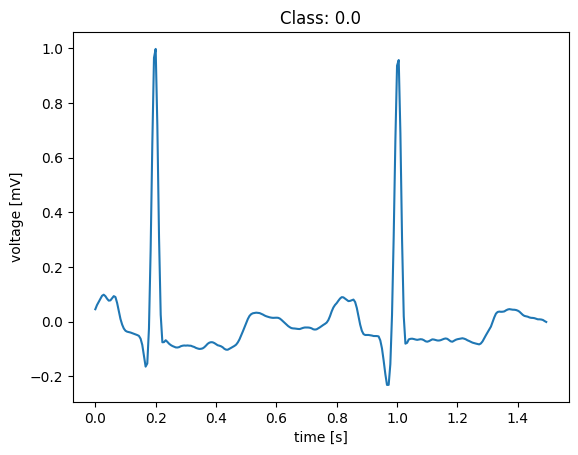

In [42]:
idx = 6494
waveform, label, *_ = test_dataset[idx]

ts = np.arange(len(waveform)) / 180  # fs = 180 Hz after downsampling
plt.plot(ts, waveform);
plt.xlabel('time [s]')
plt.ylabel('voltage [mV]');
plt.title(f'Class: {label[0]}')


In [43]:
def score_beat(idx):
    '''
    (waveform, score, predicted class, true class, boundary signals) for one test beat.

    the score is the MEAN of the readout over the labeled beat span, which is
    exactly what metrics.get_threshold calibrated the threshold on. summing over
    the whole window instead inflates the score by a factor of (end - start) and
    makes every beat cross the threshold.
    '''

    waveform, label, *stats = test_dataset[idx]

    with torch.no_grad():
        x = encoder.encode(waveform.unsqueeze(0), *stats)
        output, _, b_vals = model(x, logging=True)
        score = output[:, start:end].mean(dim=(1, 2)).item()

    return waveform, score, int(score > threshold), int(label[0]), b_vals


# the beat plotted above
waveform, score, prediction, true_class, b_vals = score_beat(idx)
print(f'idx {idx}: predicted {prediction}, real {true_class}, score {score:.4f} '
      f'(threshold {threshold:.4f})')

# candidate indices of each class for the figures below
neg_idxs = [i for i in range(300) if test_dataset[i][1][0] == 0]
pos_idxs = [i for i in range(300) if test_dataset[i][1][0] == 1]
print('normal     :', neg_idxs[:10])
print('arrhythmic :', pos_idxs[:10])


idx 6494: predicted 0, real 0, score 0.0316 (threshold 0.0869)
normal     : [0, 3, 9, 10, 11, 12, 13, 14, 15, 16]
arrhythmic : [1, 2, 4, 5, 6, 7, 8, 17, 20, 21]


In [44]:
b_0, b_1 = b_vals
b_0 = b_0.squeeze().numpy()
b_1 = b_1.squeeze().numpy()

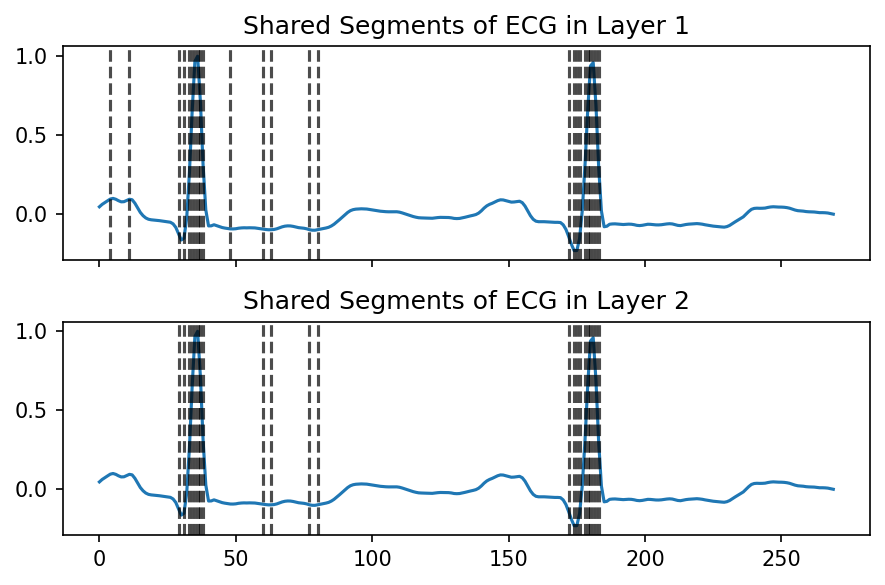

In [45]:
fig, (ax1, ax2) = plt.subplots(2, 1, sharex=True, figsize=(6, 4), gridspec_kw={'height_ratios': [3, 3]}, dpi=150)

x = np.arange(len(b_0))
b_0_indeces = np.where(b_0 == 1)[0]
event_times = x[b_0_indeces]

ax1.plot(x, waveform)
for t in event_times:
    ax1.axvline(t, color='black', linestyle='--', alpha=0.7)

b_1_indeces = np.where(b_1 == 1)[0]
event_times = x[b_1_indeces]

ax2.plot(x, waveform)
for t in event_times:
    ax2.axvline(t, color='black', linestyle='--', alpha=0.7)


ax1.set_title('Shared Segments of ECG in Layer 1')
ax2.set_title('Shared Segments of ECG in Layer 2')

fig.tight_layout()


In [46]:
# two example beats for the gate figure -- pick one of each class (see the
# candidate indices printed above; the split changed when the dataset was
# regenerated, so these indices are not necessarily the classes they used to be)
neg_idx = 3    # true 0, predicted 0
pos_idx = 21   # true 1, predicted 1

negative_waveform, neg_score, negative_prediction, neg_true, b_vals = score_beat(neg_idx)
print('Negative example -- Predicted Class: {}, Real Class: {}, score: {:.4f}'.format(
    negative_prediction, neg_true, neg_score))

neg_b_0, neg_b_1 = [b.squeeze().numpy() for b in b_vals]

positive_waveform, pos_score, positive_prediction, pos_true, b_vals = score_beat(pos_idx)
print('Positive example -- Predicted Class: {}, Real Class: {}, score: {:.4f}'.format(
    positive_prediction, pos_true, pos_score))

pos_b_0, pos_b_1 = [b.squeeze().numpy() for b in b_vals]


Negative example -- Predicted Class: 0, Real Class: 0, score: 0.0342
Positive example -- Predicted Class: 1, Real Class: 1, score: 0.4678


In [47]:
pos_example, label, *_ = test_dataset[pos_idx]

for i, (_, label, *_) in enumerate(test_dataset):
    print(i, label.max())


0 tensor(0.)
1 tensor(1.)
2 tensor(1.)
3 tensor(0.)
4 tensor(1.)
5 tensor(1.)
6 tensor(1.)
7 tensor(1.)
8 tensor(1.)
9 tensor(0.)
10 tensor(0.)
11 tensor(0.)
12 tensor(0.)
13 tensor(0.)
14 tensor(0.)
15 tensor(0.)
16 tensor(0.)
17 tensor(1.)
18 tensor(0.)
19 tensor(0.)
20 tensor(1.)
21 tensor(1.)
22 tensor(1.)
23 tensor(1.)
24 tensor(1.)
25 tensor(0.)
26 tensor(1.)
27 tensor(1.)
28 tensor(0.)
29 tensor(1.)
30 tensor(1.)
31 tensor(1.)
32 tensor(0.)
33 tensor(1.)
34 tensor(1.)
35 tensor(0.)
36 tensor(1.)
37 tensor(0.)
38 tensor(0.)
39 tensor(1.)
40 tensor(0.)
41 tensor(1.)
42 tensor(0.)
43 tensor(1.)
44 tensor(1.)
45 tensor(0.)
46 tensor(1.)
47 tensor(1.)
48 tensor(0.)
49 tensor(1.)
50 tensor(0.)
51 tensor(0.)
52 tensor(0.)
53 tensor(1.)
54 tensor(1.)
55 tensor(0.)
56 tensor(0.)
57 tensor(1.)
58 tensor(0.)
59 tensor(1.)
60 tensor(0.)
61 tensor(0.)
62 tensor(0.)
63 tensor(1.)
64 tensor(0.)
65 tensor(1.)
66 tensor(0.)
67 tensor(1.)
68 tensor(0.)
69 tensor(0.)
70 tensor(1.)
71 tensor(0.)
72

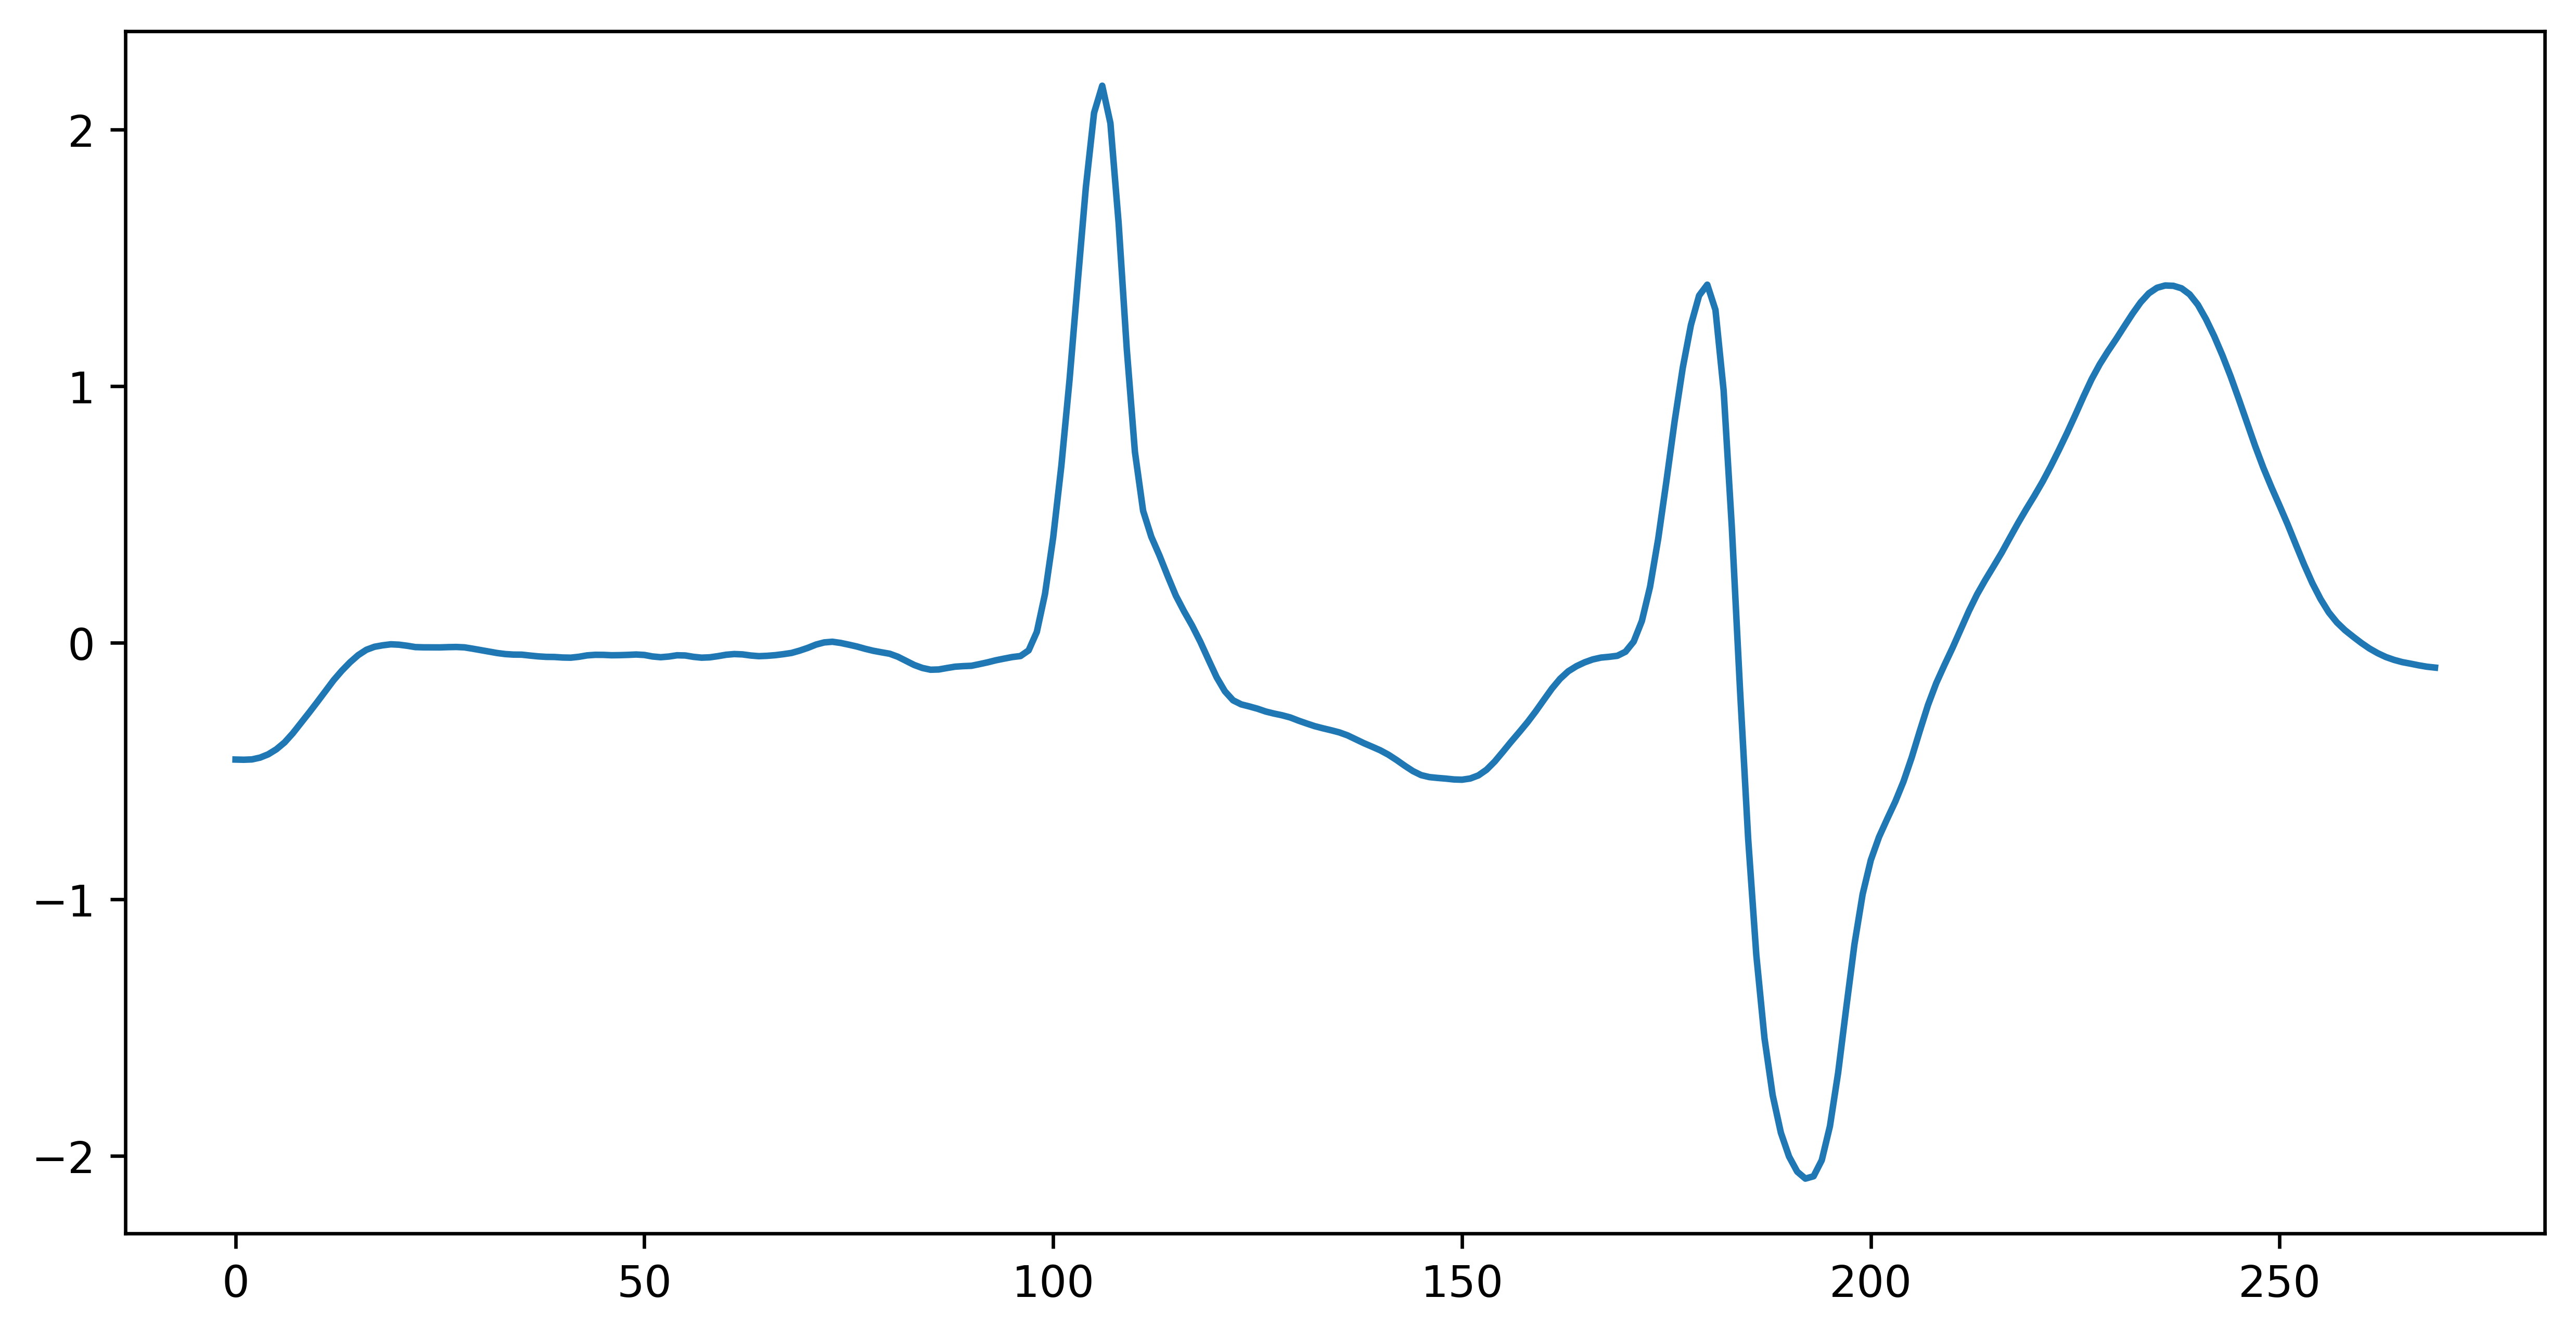

In [48]:
fig, axes = plt.subplots(1, 1, figsize=(10, 5), dpi=600)

# x axes
x_pos = np.arange(len(pos_example))

axes.plot(x_pos, pos_example)

plt.show()


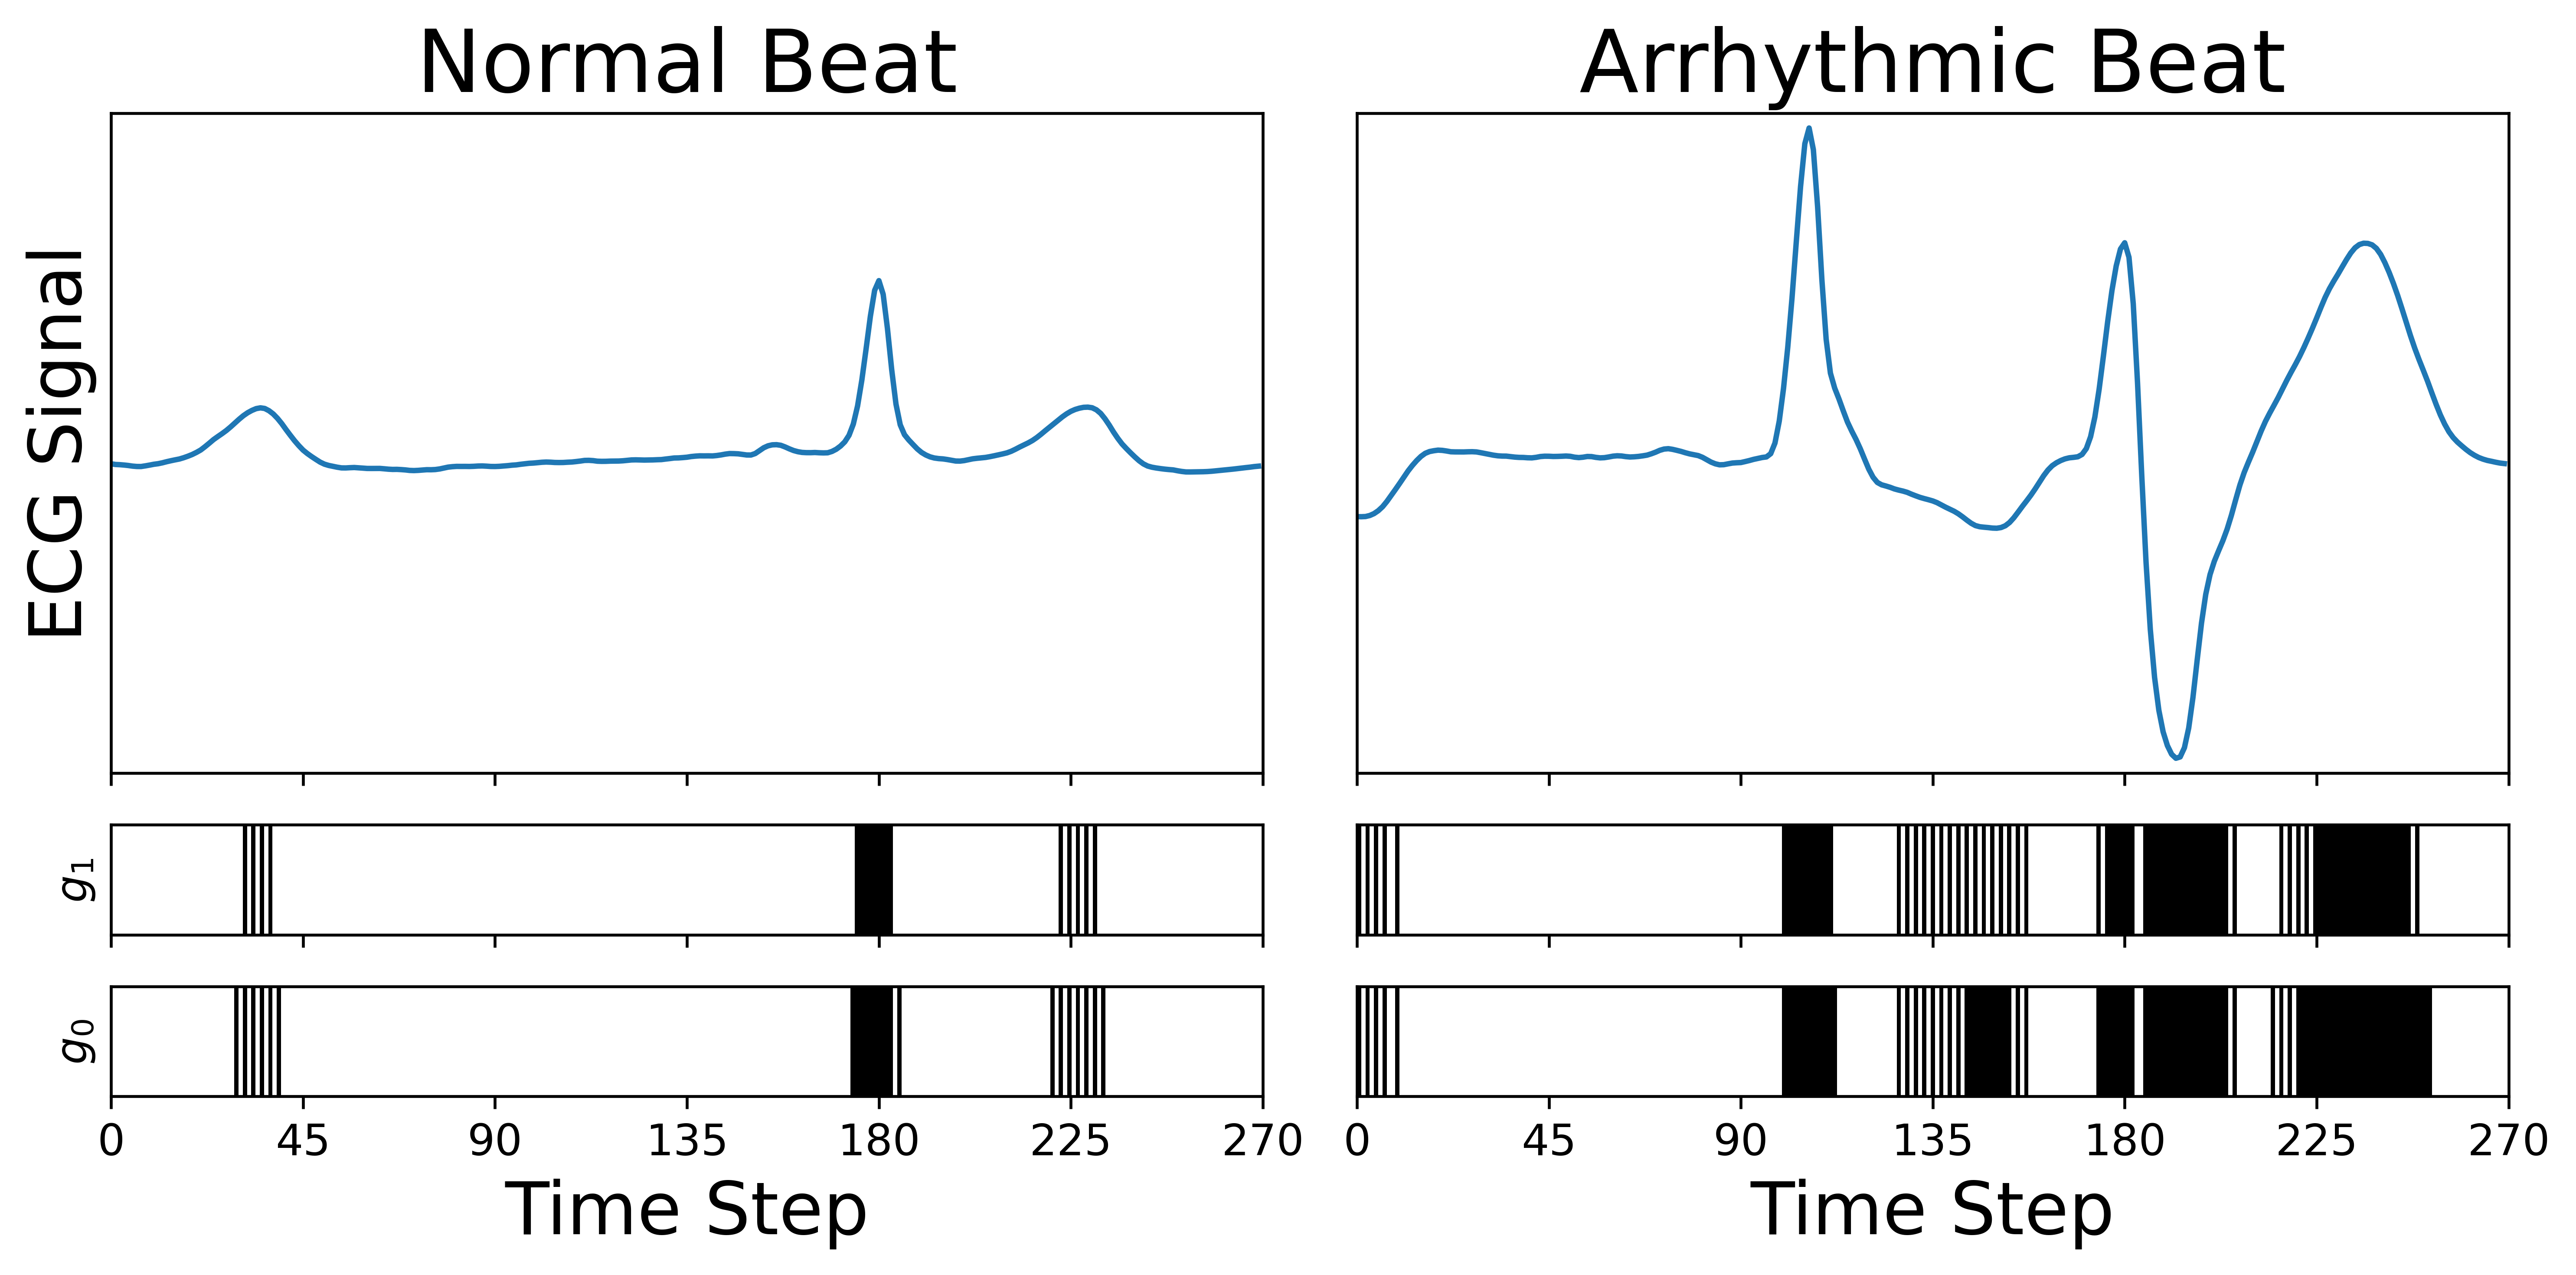

In [49]:
fig, axes = plt.subplots(
    3, 2,
    sharex='col',
    figsize=(10, 5),
    gridspec_kw={'height_ratios': [3, 0.5, 0.5]},
    dpi=600,
)

# x axes
x_neg = np.arange(len(neg_b_0))
x_pos = np.arange(len(pos_b_0))

# -------------------
# LEFT COLUMN: Negative
# -------------------
axes[0, 0].plot(x_neg, negative_waveform, )
axes[1, 0].imshow(neg_b_1[np.newaxis, :], aspect='auto', cmap='gray_r',
                  extent=[x_neg[0], x_neg[-1], 0, 1], vmin=0, vmax=1)
axes[2, 0].imshow(neg_b_0[np.newaxis, :], aspect='auto', cmap='gray_r',
                  extent=[x_neg[0], x_neg[-1], 0, 1], vmin=0, vmax=1)

# -------------------
# RIGHT COLUMN: Positive
# -------------------
axes[0, 1].plot(x_pos, positive_waveform)
axes[1, 1].imshow(pos_b_1[np.newaxis, :], aspect='auto', cmap='gray_r',
                  extent=[x_pos[0], x_pos[-1], 0, 1], vmin=0, vmax=1)
axes[2, 1].imshow(pos_b_0[np.newaxis, :], aspect='auto', cmap='gray_r',
                  extent=[x_pos[0], x_pos[-1], 0, 1], vmin=0, vmax=1)

# -------------------
# Formatting
# -------------------
n_steps = max(len(neg_b_0), len(pos_b_0))

for col in range(2):
    for row in range(3):
        axes[row, col].set_yticks([])
        axes[row, col].set_xlim(0, n_steps - 1)
        axes[row, col].set_xticks(np.arange(0, n_steps + 1, 45))
        axes[row, col].tick_params(axis='x', labelsize=12)

y_min = min(negative_waveform.min(), positive_waveform.min()) - 0.1
y_max = max(negative_waveform.max(), positive_waveform.max()) + 0.1

axes[0, 0].set_ylim(y_min, y_max)
axes[0, 1].set_ylim(y_min, y_max)

# Row labels
axes[0, 0].set_ylabel('ECG Signal', fontsize=20,)
axes[1, 0].set_ylabel('$g_1$', fontsize=12,)
axes[2, 0].set_ylabel('$g_0$', fontsize=12,)

# Column titles
axes[0, 0].set_title('Normal Beat', fontsize=24, )
axes[0, 1].set_title('Arrhythmic Beat', fontsize=24, )

# X labels
axes[2, 0].set_xlabel('Time Step', fontsize=20)
axes[2, 1].set_xlabel('Time Step', fontsize=20)

plt.tight_layout()
plt.savefig("../figures/gate_visualization_transparent.png", dpi=600, bbox_inches="tight", transparent=True)

plt.show()


## Check Linear Baseline

In [50]:
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.decomposition import PCA
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, classification_report, roc_curve, auc, confusion_matrix, ConfusionMatrixDisplay

def train_pca_lda(X_train, y_train, X_test, y_test, n_components=10):
    model = Pipeline([
        ("scaler", StandardScaler()),
        ("pca", PCA(n_components=n_components)),
        ("clf", LinearDiscriminantAnalysis())
    ])

    model.fit(X_train, y_train)

    y_pred = model.predict(X_test)

    print("Accuracy:", accuracy_score(y_test, y_pred))
    print(classification_report(y_test, y_pred))

    return model

def train_pca_logreg(X_train, y_train, X_test, y_test, n_components=10):
    model = Pipeline([
        ("scaler", StandardScaler()),
        ("pca", PCA(n_components=n_components)),
        ("clf", LogisticRegression())
    ])

    model.fit(X_train, y_train)

    y_pred = model.predict(X_test)

    print("Accuracy:", accuracy_score(y_test, y_pred))
    print(classification_report(y_test, y_pred))

    return model

def train_logreg(X_train, y_train, X_test, y_test, n_components=10):
    model = Pipeline([
        ("scaler", StandardScaler()),
        ("clf", LogisticRegression())
    ])

    model.fit(X_train, y_train)

    y_pred = model.predict(X_test)

    print("Accuracy:", accuracy_score(y_test, y_pred))
    print(classification_report(y_test, y_pred))

    return model

In [51]:
train_X = []
train_y = []

for i in range(len(train_dataset)):
    w, l, *_ = train_dataset[i]
    train_X.append(w)
    train_y.append(l[0])

train_X = np.stack(train_X)
train_y = np.stack(train_y)

test_X = []
test_y = []

for i in range(len(test_dataset)):
    w, l, *_ = test_dataset[i]
    test_X.append(w)
    test_y.append(l[0])

test_X = np.stack(test_X)
test_y = np.stack(test_y)


In [52]:
logreg_model = train_logreg(train_X, train_y, test_X, test_y, n_components=100)

Accuracy: 0.7821213262999246
              precision    recall  f1-score   support

         0.0       0.76      0.81      0.78      5172
         1.0       0.81      0.75      0.78      5444

    accuracy                           0.78     10616
   macro avg       0.78      0.78      0.78     10616
weighted avg       0.78      0.78      0.78     10616



/Users/rahul/anaconda3/envs/arr/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:406: ConvergenceWarning: lbfgs failed to converge after 100 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=100).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


0.7829369896003633


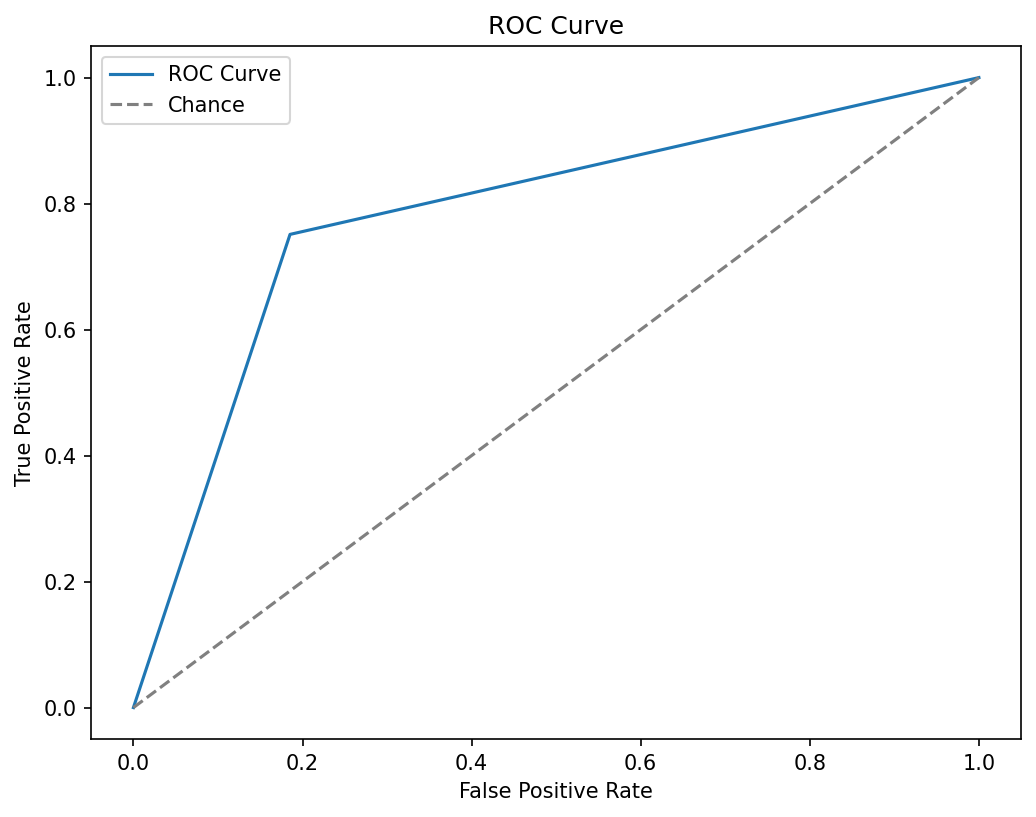

In [53]:
predictions = logreg_model.predict(test_X)

fpr, tpr, thresholds = roc_curve(test_y, predictions)

fig, ax = plt.subplots(figsize=(8, 6), dpi=150)

ax.plot(fpr, tpr, label='ROC Curve')
ax.plot([0, 1], [0, 1], linestyle='--', color='gray', label='Chance')
ax.set_xlabel('False Positive Rate')
ax.set_ylabel('True Positive Rate')
ax.set_title('ROC Curve')
ax.legend()

print(auc(fpr, tpr))

## Check Class-Wise Accuracy

In [54]:
# ../presentation_results weights predate the current beats/ dataset; these are
# the ones the remote_results/metrics csvs were computed from
weight_folder = '../remote_results/model_weights'
model_weight = 's_0_hgrsnn_wo_td'

# these weights are a four_layer_hgrsnn with a linear readout, so they only load
# into the *_large config -- a three_layer_hgrsnn would be a three-layer model
# with no separate readout and raise a shape error
with open('nested_configs/hgrsnn_large_config.yaml', 'r') as file:
    model_configs = yaml.safe_load(file)

# main.py trains with --use_best_model, i.e. config_key='xbest'. the neuron
# alphas/thresholds are constructor arguments, not state_dict entries, so
# building with the default 'x0' loads the weights without error and then
# runs them with the wrong dynamics.
model = create_model(model_configs, 'xbest')

model_path = os.path.join(weight_folder, model_weight) + '.pth'
checkpoint = torch.load(model_path, weights_only=False)
model.load_state_dict(checkpoint['model'])

val_loader = torch.utils.data.DataLoader(val_dataset, batch_size=128)
threshold = metrics.get_threshold(model, val_loader, encoder, fix_sensitivity=True,
                                  beat_bounds=(start, end))
print('threshold (recomputed):', threshold)
if 'threshold' in checkpoint:
    print('threshold (from checkpoint):', float(checkpoint['threshold']))


threshold (recomputed): 0.08334028720855713
threshold (from checkpoint): 0.08334027230739594


In [55]:
# the dataset was built with binary=True, so __getitem__ returns 0/1 labels.
# the underlying AAMI class is still in test_dataset.metadata['label'], and
# metadata rows are indexed with .iloc in __getitem__, so an unshuffled
# DataLoader walks the test set in metadata row order.
from sklearn.metrics import roc_auc_score

AAMI_CLASSES = {0: 'N (normal)', 1: 'S (supraventricular)', 2: 'V (ventricular)',
                3: 'F (fusion)'}

test_loader = torch.utils.data.DataLoader(test_dataset, batch_size=128, shuffle=False)

scores = []
model.eval()
with torch.no_grad():
    for batch in test_loader:
        # 4-tuple batches (patient_norm), so unpack the per-beat statistics and
        # hand them to the encoder the way main.py/nested_train.py do
        data, _, stats = unpack_batch(batch)
        data = encoder.encode(data, *stats).to(device)

        output, _ = model(data)

        # the same reduction get_threshold calibrated on: MEAN over the labeled
        # beat span. a sum over the whole window is (end - start) times larger
        # and puts every beat above the threshold.
        scores.append(output[:, start:end].mean(dim=(1, 2)).cpu().numpy())

scores = np.concatenate(scores)
y_pred = (scores > threshold).astype(int)

y_multi = test_dataset.metadata['label'].to_numpy()
y_binary = (y_multi > 0).astype(int)

print('Test AUC: {:.4f}'.format(roc_auc_score(y_binary, scores)))
print('Overall binary accuracy: {:.4f}'.format((y_pred == y_binary).mean()))
print('Fraction predicted positive: {:.4f}\n'.format(y_pred.mean()))

print(f"{'class':<24}{'n':>6}{'accuracy':>10}")
for c in np.unique(y_multi):
    mask = y_multi == c
    # for class 0 "correct" means predicting normal; for any other class it
    # means predicting arrhythmic, so this is recall within each true class
    acc = (y_pred[mask] == y_binary[mask]).mean()
    print(f'{AAMI_CLASSES.get(c, str(c)):<24}{mask.sum():>6}{acc:>10.4f}')


Test AUC: 0.9134
Overall binary accuracy: 0.7987
Fraction predicted positive: 0.6510

class                        n  accuracy
N (normal)                5172    0.6516
S (supraventricular)      1837    0.9015
V (ventricular)           3219    0.9652
F (fusion)                 388    0.8918


Text(0.5, 1.0, 'Class: 1.0')

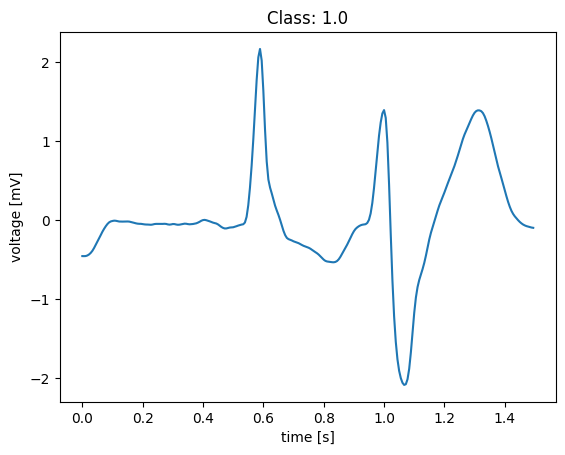

In [56]:
waveform, label, *_ = test_dataset[pos_idx]

ts = np.arange(len(waveform)) / 180
plt.plot(ts, waveform);
plt.xlabel('time [s]')
plt.ylabel('voltage [mV]');
plt.title(f'Class: {label[0]}')


In [57]:
waveform.shape

torch.Size([270])

## Interpretable spiking: what separates normal from arrhythmic beats

This section uses the binary `s_2_hgrsnn_wo_td` model (four-layer HGRSNN), the same one as the gate figure above. It's loaded under separate names (`viz_model`, `viz_threshold`), so the class-wise accuracy section, which reassigns `model`, can't change it.

The cells below:
1. run the model over the whole test set, keeping every layer's spikes and both gates
2. join each beat to its original MIT-BIH annotation (the dataset only stores the AAMI class)
3. summarize which signals separate the classes, plot class averages, then plot six single beats: a correct and an incorrect prediction for normal, supraventricular (S) and ventricular (V) beats

**How the score is built.** Layer 2 (32 neurons) feeds a linear readout at every time step. The score is that readout averaged over the scored beat span (steps 90–270; the R peak is at 180), compared against the checkpoint's threshold. The *score so far* panels plot exactly that running total, so each line ends at the beat's score.

In [58]:
# load the binary model this section visualizes and record every layer's spikes
# over the whole test set
import wfdb
import pandas as pd
from sklearn.metrics import roc_auc_score

viz_weights = '../remote_results/model_weights/s_2_hgrsnn_wo_td.pth'
with open('nested_configs/hgrsnn_large_config.yaml', 'r') as file:
    viz_configs = yaml.safe_load(file)

# kept separate from `model`, which the class-wise accuracy section reassigns
viz_model = create_model(viz_configs, 'xbest')
viz_checkpoint = torch.load(viz_weights, weights_only=False)
viz_model.load_state_dict(viz_checkpoint['model'])
viz_model.eval()

viz_threshold = float(viz_checkpoint['threshold'])

# linear readout on the 32 top-layer neurons, no bias
readout_w = viz_model.fc[0].w.detach()[0].numpy()
assert readout_w.shape == (viz_model.recurrent_dims[2],)


def run_with_state(x):
    '''
    FourLayer_HGRSNN._forward_lif unrolled so every layer's state is kept --
    model(x, logging=True) only returns the two gates.

    x: (B, T, 1) encoded input
    returns (B, T, ...) arrays: z0/z1/z2 spikes, g0/g1 gates, and evidence, the
    readout applied to the top layer at each step (its beat-span mean is the score)
    '''

    m = viz_model
    B, T, _ = x.shape
    R = m.recurrent_dims

    v0, z0, b0 = torch.zeros(B, R[0]), torch.zeros(B, R[0]), torch.zeros(B, 1)
    v1, z1, b1 = torch.zeros(B, R[1]), torch.zeros(B, R[1]), torch.zeros(B, 1)
    v2, z2 = torch.zeros(B, R[2]), torch.zeros(B, R[2])

    hist = {k: [] for k in ('z0', 'z1', 'z2', 'g0', 'g1', 'evidence')}

    with torch.no_grad():
        for t in range(T):
            v0, z0, b0 = m.bottom_cell(x[:, t, :], v0, z0, b0)
            v1, z1, b1 = m.middle_cell(z0, b0, v1, z1, b1)
            v2, z2 = m.top_cell(z1, b1, v2, z2)

            for k, val in (('z0', z0), ('z1', z1), ('z2', z2), ('g0', b0[:, 0]),
                           ('g1', b1[:, 0]), ('evidence', m.fc(z2)[:, 0])):
                hist[k].append(val)

    return {k: torch.stack(v, 1).numpy() for k, v in hist.items()}


test_meta = test_dataset.metadata.reset_index(drop=True)
viz_loader = torch.utils.data.DataLoader(test_dataset, batch_size=256, shuffle=False)

acts = {k: [] for k in ('waveform', 'score', 'rate0', 'rate1', 'rate2', 'g0', 'g1',
                        'top_rate', 'evidence')}

for i, batch in enumerate(viz_loader):
    data, _, stats = unpack_batch(batch)
    x = encoder.encode(data, *stats)
    state = run_with_state(x)

    if i == 0:
        with torch.no_grad():
            reference, _ = viz_model(x)
        assert np.allclose(reference[..., 0].numpy(), state['evidence'], atol=1e-6), \
            'unrolled forward disagrees with the model'

    acts['waveform'].append(x[..., 0].numpy())
    acts['score'].append(state['evidence'][:, start:end].mean(1))
    for k in ('0', '1', '2'):
        acts['rate' + k].append(state['z' + k][:, start:end].mean(1))   # per-neuron rate in the beat span
    acts['g0'].append(state['g0'])
    acts['g1'].append(state['g1'])
    acts['top_rate'].append(state['z2'].mean(2))                        # top-layer population rate per step
    acts['evidence'].append(state['evidence'])

acts = {k: np.concatenate(v) for k, v in acts.items()}
viz_pred = acts['score'] > viz_threshold
aami = test_meta['label'].to_numpy()   # 0 N, 1 S, 2 V, 3 F
viz_y = (aami > 0).astype(int)

print(f'{len(viz_y)} test beats | AUC {roc_auc_score(viz_y, acts["score"]):.4f} | '
      f'accuracy {(viz_pred == viz_y).mean():.4f} at threshold {viz_threshold:.4f}')


10616 test beats | AUC 0.9113 | accuracy 0.7833 at threshold 0.0869


In [59]:
# the dataset keeps only the AAMI class, which hides which beat type each one was
# (bundle-branch-block beats are AAMI "normal", for instance). recover the original
# MIT-BIH symbol and the RR intervals around every test beat. beat_sample is the
# R peak at the downsampled rate, so annotation samples are scaled the same way.
mitdb = '../mit-bih-arrhythmia-database-1.0.0'
downsample = 360 // int(test_meta['fs'].iloc[0])

# PhysioNet beat annotation codes (non-beat annotations like rhythm changes are skipped)
PHYSIONET_BEATS = set('NLRBAaJSVrFejnE/fQ?')

beat_symbol = np.empty(len(test_meta), dtype=object)
rr_prev = np.full(len(test_meta), np.nan)    # samples since the previous beat
rr_local = np.full(len(test_meta), np.nan)   # median RR over the surrounding 16 beats

for record_id, rows in test_meta.groupby('patient').groups.items():
    ann = wfdb.rdann(f'{mitdb}/{record_id}', 'atr')
    symbols = np.array(ann.symbol)
    is_beat = np.isin(symbols, list(PHYSIONET_BEATS))
    samples = np.array(ann.sample)[is_beat] // downsample
    symbols = symbols[is_beat]
    position = {int(s): k for k, s in enumerate(samples)}

    for r in rows:
        k = position[int(test_meta.at[r, 'beat_sample'])]
        beat_symbol[r] = symbols[k]
        if k > 0:
            rr_prev[r] = samples[k] - samples[k - 1]
        lo, hi = max(k - 8, 1), min(k + 8, len(samples) - 1)
        rr_local[r] = np.median(np.diff(samples[lo - 1:hi + 1]))

beat_symbol = beat_symbol.astype(str)
prematurity = rr_prev / rr_local   # < 1 means the beat came early
record = test_meta['patient'].to_numpy()

# the dataset's AAMI label has to agree with the symbol for the join to be right
AAMI = {'N': 0, 'L': 0, 'R': 0, 'e': 0, 'j': 0, 'A': 1, 'a': 1, 'J': 1, 'S': 1, 'V': 2, 'E': 2, 'F': 3}
assert all(AAMI[s] == l for s, l in zip(beat_symbol, aami)), 'symbol/label mismatch'

print('test beats by MIT-BIH symbol:', pd.Series(beat_symbol).value_counts().to_dict())


test beats by MIT-BIH symbol: {'N': 4310, 'V': 3218, 'A': 1736, 'L': 445, 'R': 398, 'F': 388, 'J': 51, 'a': 50, 'j': 19, 'E': 1}


In [60]:
# what the spiking activity encodes, measured over the whole test set

# --- 1. which neurons carry the decision --- #
# selectivity = AUC of a neuron's beat-span rate for normal vs arrhythmic.
# 0.5 is unselective, > 0.8 fires more for arrhythmic beats, < 0.2 more for normal ones.
active = {k: acts[f'rate{k}'].mean(0) > 1e-3 for k in (0, 1, 2)}
selectivity = {
    k: np.array([roc_auc_score(viz_y, r) if a else np.nan
                 for r, a in zip(acts[f'rate{k}'].T, active[k])])
    for k in (0, 1, 2)
}

for k in (0, 1, 2):
    s_k = selectivity[k][active[k]]
    print(f'layer {k}: {active[k].sum():2d}/{len(active[k])} neurons active | '
          f'{(s_k > 0.8).sum():2d} arrhythmia-selective (AUC > 0.8) | '
          f'{(s_k < 0.2).sum()} normal-selective (AUC < 0.2) | '
          f'selectivity range {np.nanmin(s_k):.2f}-{np.nanmax(s_k):.2f}')

print(f'\nlayer 2: {(readout_w < 0).sum()} neurons have a negative readout weight and '
      f'{(active[2] & (readout_w < 0)).sum()} of them ever fire; the {active[2].sum()} active neurons have weights '
      f'{[round(float(w), 2) for w in readout_w[active[2]]]}')

# --- 2. predictions by original beat type --- #
by_symbol = (pd.DataFrame({'AAMI': pd.Series(aami).map({0: 'N', 1: 'S', 2: 'V', 3: 'F'}),
                           'symbol': beat_symbol, 'predicted_arrhythmic': viz_pred})
             .groupby(['AAMI', 'symbol'])['predicted_arrhythmic']
             .agg(n='size', frac_predicted_arrhythmic='mean')
             .round(3))
print()
print(by_symbol.to_string())

# --- 3. where in the beat the evidence comes from --- #
segments = {'before QRS [90,165)': slice(90, 165), 'QRS [165,195)': slice(165, 195),
            'after QRS [195,270)': slice(195, 270)}
groups = {
    'N  predicted normal':     (beat_symbol == 'N') & ~viz_pred,
    'N  predicted arrhythmic': (beat_symbol == 'N') & viz_pred,
    'R  predicted arrhythmic': (beat_symbol == 'R') & viz_pred,
    'A  predicted arrhythmic': (beat_symbol == 'A') & viz_pred,
    'A  predicted normal':     (beat_symbol == 'A') & ~viz_pred,
    'V  predicted arrhythmic': (beat_symbol == 'V') & viz_pred,
    'V  predicted normal':     (beat_symbol == 'V') & ~viz_pred,
}
print('\nshare of each group\'s evidence by segment of the scored span, and median score')
for name, m in groups.items():
    total = acts['evidence'][m, start:end].sum()
    shares = '  '.join(f'{seg} {acts["evidence"][m, sl].sum() / total:.2f}' for seg, sl in segments.items())
    print(f'{name:25s} n={m.sum():5d}  median score {np.median(acts["score"][m]):.3f}  {shares}')

# --- 4. morphology or timing? --- #
# morphology: correlation of the QRS window with the mean plain-N beat of the same
# record (1 = identical shape to that patient's normal beats). timing: prematurity.
qrs = slice(160, 230)
normal_template = {r: acts['waveform'][(record == r) & (beat_symbol == 'N'), qrs].mean(0)
                   for r in np.unique(record) if ((record == r) & (beat_symbol == 'N')).sum() >= 20}
shape_similarity = np.array([np.corrcoef(acts['waveform'][i, qrs], normal_template[r])[0, 1]
                             if r in normal_template else np.nan for i, r in enumerate(record)])

print('\nwhat predicts whether an arrhythmic beat is detected (AUC; 0.5 = no information)')
for name, m in (('A beats, excluding record 232', (beat_symbol == 'A') & (record != 232)),
                ('V beats', beat_symbol == 'V')):
    m = m & ~np.isnan(shape_similarity) & ~np.isnan(prematurity)
    print(f'{name:31s} n={m.sum():4d}  detected {viz_pred[m].mean():.2f} | '
          f'shape unlike own normals {roc_auc_score(viz_pred[m], -shape_similarity[m]):.2f} | '
          f'prematurity {roc_auc_score(viz_pred[m], -prematurity[m]):.2f}')

m232 = (beat_symbol == 'A') & (record == 232)
print(f'record 232: {m232.sum()} of {(beat_symbol == "A").sum()} A beats, detected {viz_pred[m232].mean():.2f}, '
      f'median prematurity {np.nanmedian(prematurity[m232]):.2f}')

# --- 5. does a detection come from the beat itself? --- #
# share of the score earned from the QRS onward (step 165 to the end of the span)
own_beat_share = acts['evidence'][:, 165:end].sum(1) / (acts['evidence'][:, start:end].sum(1) + 1e-9)
premature = prematurity < 0.85
pool = (beat_symbol == 'A') & viz_pred & premature & (record != 232)
print(f'\ndetected premature (RR < 0.85x local) A beats outside record 232: {pool.sum()}, of which '
      f'{(pool & (own_beat_share >= 0.7)).sum()} ({(pool & (own_beat_share >= 0.7)).mean() / pool.mean():.2f}) '
      f'earn >= 70% of their score from the QRS onward (median share {np.median(own_beat_share[pool]):.2f}; '
      f'correctly predicted plain N: {np.median(own_beat_share[(beat_symbol == "N") & ~viz_pred]):.2f})')


layer 0: 24/32 neurons active | 16 arrhythmia-selective (AUC > 0.8) | 0 normal-selective (AUC < 0.2) | selectivity range 0.48-0.90
layer 1: 43/64 neurons active | 24 arrhythmia-selective (AUC > 0.8) | 0 normal-selective (AUC < 0.2) | selectivity range 0.49-0.92
layer 2: 10/32 neurons active |  9 arrhythmia-selective (AUC > 0.8) | 0 normal-selective (AUC < 0.2) | selectivity range 0.78-0.91

layer 2: 16 neurons have a negative readout weight and 0 of them ever fire; the 10 active neurons have weights [0.28, 0.04, 0.32, 0.05, 0.5, 0.4, 0.28, 0.15, 0.24, 0.07]

                n  frac_predicted_arrhythmic
AAMI symbol                                 
F    F        388                      0.874
N    L        445                      0.566
     N       4310                      0.296
     R        398                      0.997
     j         19                      0.684
S    A       1736                      0.921
     J         51                      0.275
     a         50             

### What the summary shows

- **Normal means silence, not a pattern.** Only 10 of the 32 layer-2 neurons ever fire, and none of the 16 with a negative readout weight does. The readout can therefore only add evidence for *arrhythmic*: a beat is called normal when the network stays quiet. No neuron in any layer prefers normal beats (lowest selectivity 0.48). Most active neurons prefer arrhythmic beats: 16 of 24 in layer 0, 24 of 43 in layer 1, 9 of 10 in layer 2.
- **The decision happens after the R peak.** Correctly classified normal beats earn 77% of their small score during the QRS and 17% after it. Detected V beats earn 50% after the QRS.
- **Bundle-branch-block beats are the systematic false positive.** AAMI counts them as normal, but 99.7% of right (R) and 56.6% of left (L) bundle-branch-block beats are predicted arrhythmic, against 29.6% of plain N beats. Plain-N false positives also earn 30% of their score before the QRS (6% for correct normals), often from the neighbouring beat inside the window.
- **The network reads shape, not timing.** For A beats outside record 232, detection is predicted by how different the QRS looks from that patient's own normal beats (AUC 0.83), and only weakly by how premature the beat is (0.60). Record 232 holds 1382 of the 1736 A beats. All of them are detected, although they are not premature (median RR 0.99× local), so that record's shape, not rhythm, carries most of the S-class accuracy.
- **Many S detections don't come from the beat itself.** Of 165 detected premature A beats outside record 232, only 30% earn at least 70% of their score from their own QRS onward. The median share is 0.56, against 1.00 for correctly classified normal beats.

### Class averages over the window

One column per beat type, averaged over every test beat of that type; each row shares its y-axis across columns.

Gates open at every QRS for every beat type; that's the segmentation seen in the gate figure above. The beat types separate after the R peak. For plain N beats, the gates close within a few steps and layer 2 goes quiet, so the average score stays under the threshold. For R, A and V beats, the gates stay open and layer 2 keeps firing through the wide or abnormal QRS and repolarization, so the score climbs past the threshold between steps 180 and 230. Activity before step 90 (e.g. the preceding beat near step 55 for A beats) is outside the scored span and doesn't count.

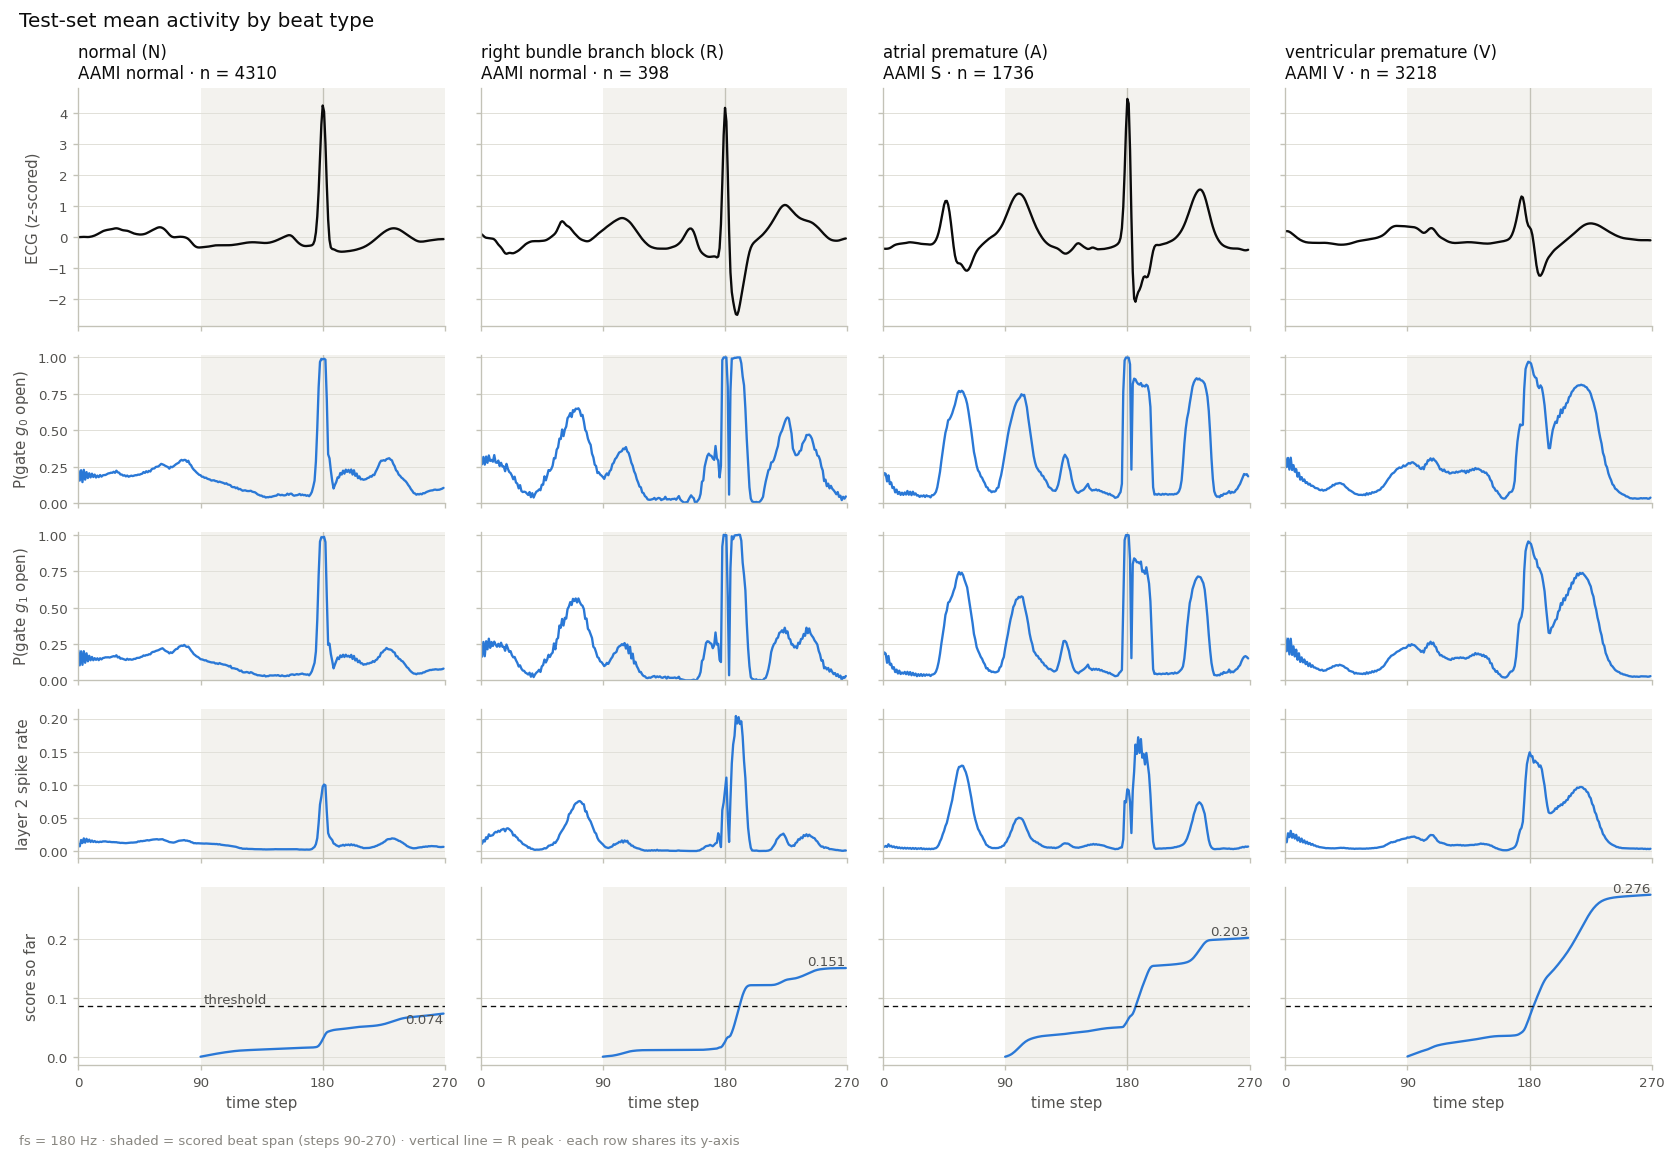

In [61]:
# class-mean activity across the window, one column per original beat type
INK, INK_2, MUTED, AXIS, GRID, SPAN = '#0b0b0b', '#52514e', '#898781', '#c3c2b7', '#e1e0d9', '#f3f2ee'
SERIES = '#2a78d6'

# R beats are labeled normal but shown separately because the network treats them
# like arrhythmic beats
BEAT_GROUPS = {
    'N': ('normal (N)', 'AAMI normal'),
    'R': ('right bundle branch block (R)', 'AAMI normal'),
    'A': ('atrial premature (A)', 'AAMI S'),
    'V': ('ventricular premature (V)', 'AAMI V'),
}

r_peak = start + (end - start) // 2   # the beat span is centered on the R annotation


def style_axis(ax, ylabel=None):
    for side in ('top', 'right'):
        ax.spines[side].set_visible(False)
    for side in ('left', 'bottom'):
        ax.spines[side].set_color(AXIS)
        ax.spines[side].set_linewidth(0.8)
    ax.tick_params(colors=AXIS, labelcolor=INK_2, labelsize=8, length=3)
    ax.grid(axis='y', color=GRID, linewidth=0.6)
    ax.set_axisbelow(True)
    if ylabel:
        ax.set_ylabel(ylabel, color=INK_2, fontsize=9)


def mark_window(ax):
    ax.axvspan(start, end, color=SPAN, zorder=0, lw=0)
    ax.axvline(r_peak, color=AXIS, lw=0.8, zorder=1)


T = acts['waveform'].shape[1]
t = np.arange(T)

# score so far only exists inside the scored span: (beats, end - start)
cumulative = np.cumsum(acts['evidence'][:, start:end], axis=1) / (end - start)

rows = [
    ('ECG (z-scored)', t, acts['waveform'], INK),
    ('P(gate $g_0$ open)', t, acts['g0'], SERIES),
    ('P(gate $g_1$ open)', t, acts['g1'], SERIES),
    ('layer 2 spike rate', t, acts['top_rate'], SERIES),
    ('score so far', np.arange(start, end), cumulative, SERIES),
]

fig, axes = plt.subplots(len(rows), len(BEAT_GROUPS), figsize=(14, 9.5), sharex=True, sharey='row',
                         dpi=120, gridspec_kw={'height_ratios': [1.6, 1, 1, 1, 1.2]})

for col, (symbol, (name, aami_class)) in enumerate(BEAT_GROUPS.items()):
    m = beat_symbol == symbol

    for row, (ylabel, x, values, color) in enumerate(rows):
        ax = axes[row, col]
        mark_window(ax)
        ax.plot(x, values[m].mean(axis=0), color=color, lw=1.4, solid_capstyle='round')
        style_axis(ax, ylabel if col == 0 else None)

    axes[0, col].set_title(f'{name}\n{aami_class} · n = {m.sum()}', color=INK, fontsize=10, loc='left')

    score_ax = axes[-1, col]
    score_ax.axhline(viz_threshold, color=INK, lw=0.8, ls=(0, (4, 3)))
    final = cumulative[m, -1].mean()
    # label above the line's end, or below it when that would sit on the threshold line
    score_ax.text(T - 1, final, f'{final:.3f}', color=INK_2, fontsize=8, ha='right',
                  va='top' if final < viz_threshold else 'bottom')
    score_ax.set_xlabel('time step', color=INK_2, fontsize=9)

axes[-1, 0].text(start + 2, viz_threshold, 'threshold', color=INK_2, fontsize=8, ha='left', va='bottom')
axes[1, 0].set_ylim(0, 1.02)
axes[2, 0].set_ylim(0, 1.02)
axes[-1, 0].set_xlim(0, T - 1)
axes[-1, 0].set_xticks(np.arange(0, T + 1, 90))

fig.suptitle('Test-set mean activity by beat type', x=0.01, ha='left', color=INK, fontsize=12)
fig.text(0.01, -0.005, 'fs = 180 Hz · shaded = scored beat span (steps 90-270) · vertical line = R peak · '
         'each row shares its y-axis', color=MUTED, fontsize=8, ha='left', va='top')
fig.tight_layout()
plt.show()


### Six example beats

Each figure puts a correct and an incorrect prediction side by side. Rows from top:
- the z-scored ECG, with the previous R peak marked when it falls in the window
- the two gates
- spike rasters for layers 0–2: only neurons that fire somewhere in the test set, most arrhythmia-selective at the top, black if selectivity AUC > 0.8
- the score accumulating over the scored span

Titles give the beat's MIT-BIH symbol and record, its score, its RR interval relative to the local rhythm (< 1 = premature), and how closely its QRS matches that patient's normal beats (r).

The beats come from the candidate lists at the end of this section: clean signal, one per record, ranked by the rule for each category. For the correct S example, the top candidates reached the threshold on a baseline dip *before* the premature beat. So that rule also requires at least 70% of the score to come from the beat's own QRS onward.

In [62]:
# example beats: a correct and an incorrect prediction for normal, supraventricular
# and ventricular beats. rasters show only neurons that fire somewhere in the test
# set, sorted so the most arrhythmia-selective are at the top.
SELECTIVE = '#0b0b0b'      # neuron with selectivity AUC > 0.8
UNSELECTIVE = '#c3c2b7'
SCORE = '#2a78d6'

EXAMPLES = {
    'normal':           [('correct', 1771), ('incorrect', 1372)],
    'supraventricular': [('correct', 6287), ('incorrect', 4085)],
    'ventricular':      [('correct', 4243), ('incorrect', 4946)],
}

EXPECTED_SYMBOLS = {'normal': {'N', 'L', 'R', 'e', 'j'}, 'supraventricular': {'A', 'a', 'J', 'S'},
                    'ventricular': {'V', 'E'}}


def check_examples(examples):
    # fail loudly if the split changes and an index stops being what the text says it is
    for group, pair in examples.items():
        for outcome, i in pair:
            assert beat_symbol[i] in EXPECTED_SYMBOLS[group], (group, i, beat_symbol[i])
            assert (viz_pred[i] == (group != 'normal')) == (outcome == 'correct'), (group, outcome, i)


def plot_beats(title, beats):
    '''one column per (label, test index): ECG, both gates, every layer's spikes, and the score'''
    states = [run_with_state(torch.tensor(acts['waveform'][i], dtype=torch.float32)[None, :, None])
              for _, i in beats]
    so_far = [np.cumsum(s['evidence'][0, start:end]) / (end - start) for s in states]
    score_max = max(max(c.max() for c in so_far), viz_threshold) * 1.25

    rows = [('ECG (z-scored)', 2.2), ('$g_0$', 0.28), ('$g_1$', 0.28), ('layer 0', 1.1),
            ('layer 1', 1.6), ('layer 2', 0.8), ('score so far', 1.2)]
    fig, axes = plt.subplots(len(rows), len(beats), figsize=(5.6 * len(beats), 10.5), sharex=True,
                             dpi=120, squeeze=False, gridspec_kw={'height_ratios': [h for _, h in rows]})

    for col, ((label, i), state, cum) in enumerate(zip(beats, states, so_far)):
        ax = axes[:, col]
        predicted = 'arrhythmic' if viz_pred[i] else 'normal'

        # ECG
        mark_window(ax[0])
        ax[0].plot(t, acts['waveform'][i], color=INK, lw=1.1)
        if not np.isnan(rr_prev[i]) and r_peak - rr_prev[i] >= 0:
            prev = r_peak - rr_prev[i]
            ax[0].axvline(prev, color=AXIS, lw=0.8)
            ax[0].text(prev + 2, ax[0].get_ylim()[1], 'previous R', color=MUTED, fontsize=7, va='top')
        ax[0].set_title(f'{label}: beat {beat_symbol[i]}, record {record[i]}, test idx {i}\n'
                        f'score {acts["score"][i]:.3f} → predicted {predicted}\n'
                        f'RR {prematurity[i]:.2f}× local · QRS r = {shape_similarity[i]:.2f} vs own normals',
                        color=INK, fontsize=8.5, loc='left')

        # gates
        for row, key in ((1, 'g0'), (2, 'g1')):
            ax[row].imshow(state[key][0][None, :], aspect='auto', cmap='Greys', vmin=0, vmax=1,
                           extent=[0, T - 1, 0, 1], interpolation='nearest')
            ax[row].set_yticks([])

        # spike rasters
        for row, k in ((3, 0), (4, 1), (5, 2)):
            order = np.where(active[k])[0]
            order = order[np.argsort(selectivity[k][order])]
            times, rank = np.nonzero(state[f'z{k}'][0][:, order])
            strong = selectivity[k][order][rank] > 0.8
            for mask, color in ((~strong, UNSELECTIVE), (strong, SELECTIVE)):
                ax[row].scatter(times[mask], rank[mask], marker='|', s=7, linewidths=0.7, color=color)
            ax[row].axvspan(start, end, color=SPAN, zorder=0, lw=0)
            ax[row].set_ylim(-1, len(order))
            ax[row].set_yticks([])

        # score accumulating over the beat span
        mark_window(ax[6])
        ax[6].plot(np.arange(start, end), cum, color=SCORE, lw=1.8, solid_capstyle='round')
        ax[6].axhline(viz_threshold, color=INK, lw=0.8, ls=(0, (4, 3)))
        ax[6].text(T - 1, viz_threshold, 'threshold', color=INK_2, fontsize=7, ha='right', va='bottom')
        ax[6].set_ylim(0, score_max)

        for a in ax:
            style_axis(a)
            a.grid(False)
        for a in ax[1:6]:
            a.spines['left'].set_visible(False)

    for a, (label, _) in zip(axes[:, 0], rows):
        a.set_ylabel(label, color=INK_2, fontsize=9, rotation=0, ha='right', va='center')
    for a in axes[-1]:
        a.set_xlim(0, T - 1)
        a.set_xticks(np.arange(0, T + 1, 45))
        a.set_xlabel('time step (fs = 180 Hz)', color=INK_2, fontsize=9)

    fig.suptitle(title, x=0.01, ha='left', color=INK, fontsize=12)
    fig.text(0.01, -0.005, 'rasters: black = arrhythmia-selective neuron (AUC > 0.8), gray = less selective; '
             'silent neurons omitted · shaded = scored beat span · vertical line = R peak',
             color=MUTED, fontsize=8, ha='left', va='top')
    fig.tight_layout()
    plt.show()


def plot_pair(group):
    plot_beats(f'{group.capitalize()} beats: correct vs incorrect prediction', EXAMPLES[group])


check_examples(EXAMPLES)


#### Normal vs arrhythmic beat

The original gate figure from the top of the notebook, redrawn with the correct normal beat (record 221) and the correct ventricular beat (record 228) from the examples in this section. Like the original, it plots the raw ECG with the two gates underneath. The shaded region is the scored beat span (steps 90–270), the part of the window the score is computed over; everything before it is context the model sees but isn't scored on. It saves to `../figures/gate_visualization_normal_vs_arrhythmic.png`, so the original figure file isn't overwritten.

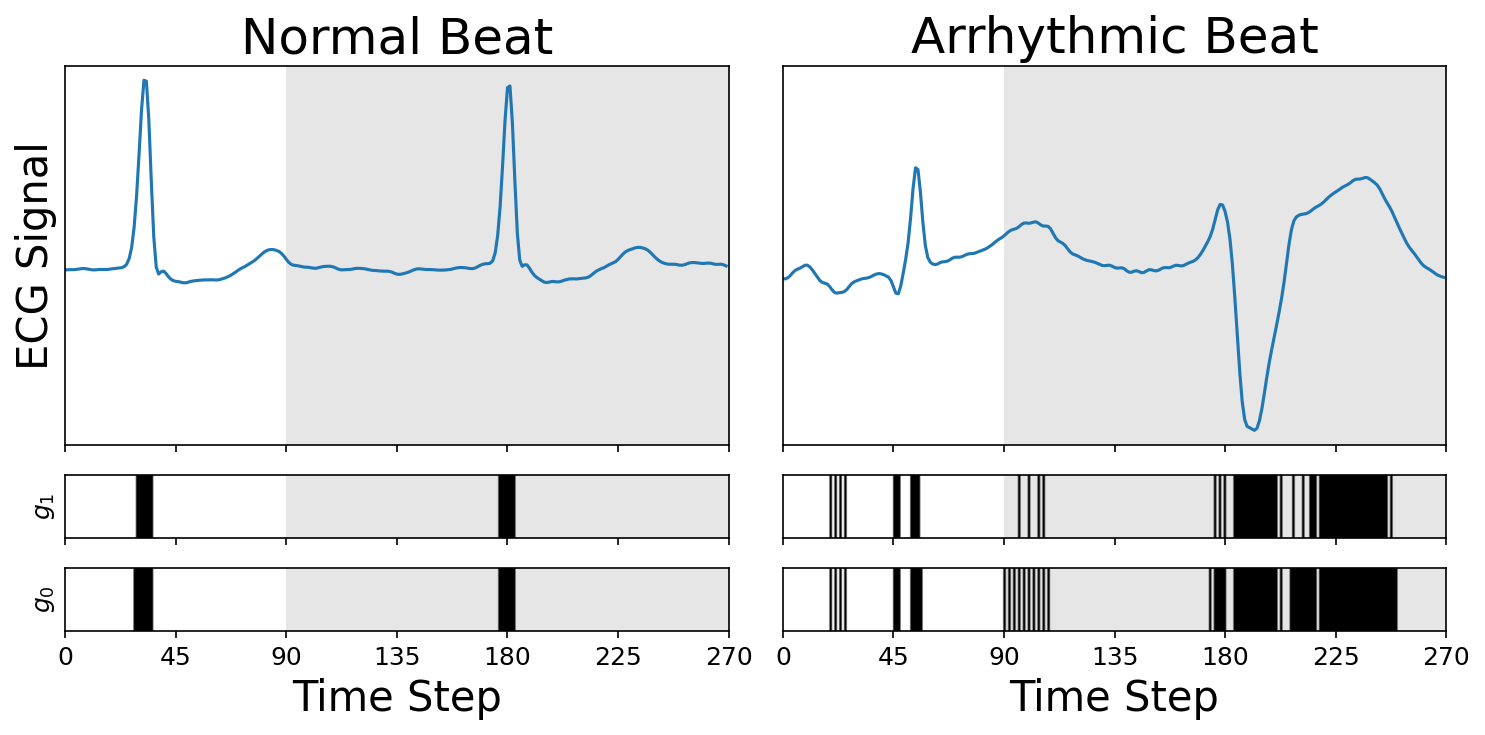

In [63]:
# the original gate figure, redrawn with the clearest pair from EXAMPLES. new variable
# names so rerunning the original figure cell still draws its own beats.
normal_idx = EXAMPLES['normal'][0][1]           # correct: plain N, predicted normal
arrhythmic_idx = EXAMPLES['ventricular'][0][1]  # correct: V, predicted arrhythmic


def gates_for(idx):
    state = run_with_state(torch.tensor(acts['waveform'][idx], dtype=torch.float32)[None, :, None])
    return state['g0'][0], state['g1'][0]


normal_waveform = test_dataset[normal_idx][0].numpy()
arrhythmic_waveform = test_dataset[arrhythmic_idx][0].numpy()
normal_g0, normal_g1 = gates_for(normal_idx)
arrhythmic_g0, arrhythmic_g1 = gates_for(arrhythmic_idx)

fig, axes = plt.subplots(
    3, 2,
    sharex='col',
    figsize=(10, 5),
    gridspec_kw={'height_ratios': [3, 0.5, 0.5]},
    dpi=150,
)

x_normal = np.arange(len(normal_g0))
x_arrhythmic = np.arange(len(arrhythmic_g0))

# -------------------
# LEFT COLUMN: Normal
# -------------------
axes[0, 0].plot(x_normal, normal_waveform)
axes[1, 0].imshow(np.ma.masked_equal(normal_g1[np.newaxis, :], 0), aspect='auto', cmap='gray_r',
                  extent=[x_normal[0], x_normal[-1], 0, 1], vmin=0, vmax=1, zorder=1)
axes[2, 0].imshow(np.ma.masked_equal(normal_g0[np.newaxis, :], 0), aspect='auto', cmap='gray_r',
                  extent=[x_normal[0], x_normal[-1], 0, 1], vmin=0, vmax=1, zorder=1)

# -------------------
# RIGHT COLUMN: Arrhythmic
# -------------------
axes[0, 1].plot(x_arrhythmic, arrhythmic_waveform)
axes[1, 1].imshow(np.ma.masked_equal(arrhythmic_g1[np.newaxis, :], 0), aspect='auto', cmap='gray_r',
                  extent=[x_arrhythmic[0], x_arrhythmic[-1], 0, 1], vmin=0, vmax=1, zorder=1)
axes[2, 1].imshow(np.ma.masked_equal(arrhythmic_g0[np.newaxis, :], 0), aspect='auto', cmap='gray_r',
                  extent=[x_arrhythmic[0], x_arrhythmic[-1], 0, 1], vmin=0, vmax=1, zorder=1)

# shade the scored beat span (the part of the window the score is computed over)
# behind every row. closed gates are transparent, so they read white outside the
# span and gray inside it; the white span keeps them white in the transparent export.
for col in range(2):
    for row in range(3):
        axes[row, col].axvspan(start, end, color='0.9', lw=0, zorder=0)
    for row in (1, 2):
        axes[row, col].axvspan(0, start, color='white', lw=0, zorder=0)

# -------------------
# Formatting
# -------------------
n_steps = max(len(normal_g0), len(arrhythmic_g0))

for col in range(2):
    for row in range(3):
        axes[row, col].set_yticks([])
        axes[row, col].set_xlim(0, n_steps - 1)
        axes[row, col].set_xticks(np.arange(0, n_steps + 1, 45))
        axes[row, col].tick_params(axis='x', labelsize=12)

y_min = min(normal_waveform.min(), arrhythmic_waveform.min()) - 0.1
y_max = max(normal_waveform.max(), arrhythmic_waveform.max()) + 0.1

axes[0, 0].set_ylim(y_min, y_max)
axes[0, 1].set_ylim(y_min, y_max)

# Row labels
axes[0, 0].set_ylabel('ECG Signal', fontsize=20)
axes[1, 0].set_ylabel('$g_1$', fontsize=12)
axes[2, 0].set_ylabel('$g_0$', fontsize=12)

# Column titles
axes[0, 0].set_title('Normal Beat', fontsize=24)
axes[0, 1].set_title('Arrhythmic Beat', fontsize=24)

# X labels
axes[2, 0].set_xlabel('Time Step', fontsize=20)
axes[2, 1].set_xlabel('Time Step', fontsize=20)

plt.tight_layout()
plt.savefig("../figures/gate_visualization_normal_vs_arrhythmic.png", dpi=600, bbox_inches="tight", transparent=True)

plt.show()


#### Gating activity by outcome

The figure above for all six examples. Rows are the beat classes and columns the correct and incorrect prediction: for normal beats a true negative and a false positive, for supraventricular and ventricular beats a true positive and a false negative. The shaded region is the scored beat span. It saves to `../figures/gate_visualization_outcomes.png`.

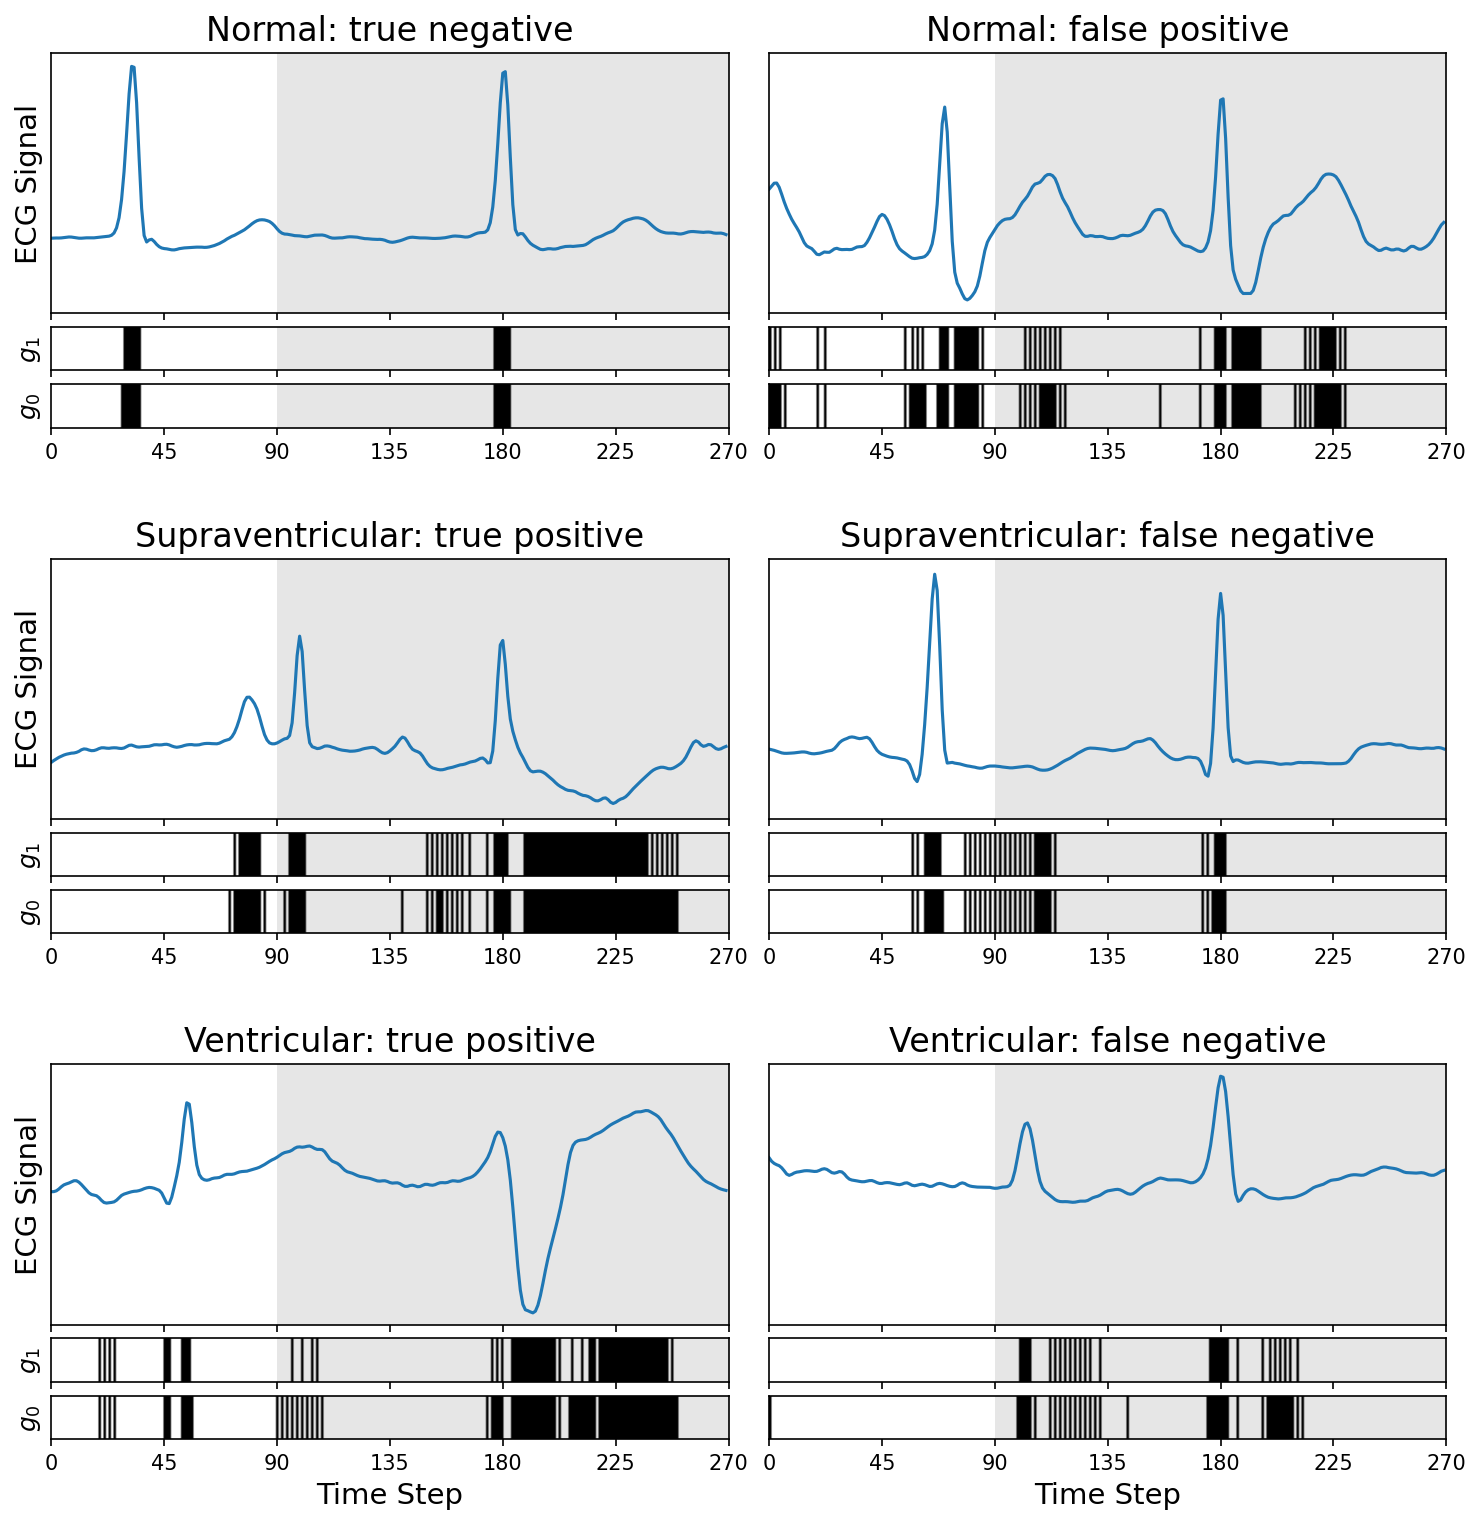

In [64]:
# gating activity for every outcome, in the style of the normal vs arrhythmic figure
# (uses gates_for from that cell). a correct call on a normal beat is a true negative
# and an incorrect one a false positive; for arrhythmic beats, a true positive and a
# false negative.
OUTCOME_NAMES = {
    ('normal', 'correct'): 'true negative',
    ('normal', 'incorrect'): 'false positive',
    ('supraventricular', 'correct'): 'true positive',
    ('supraventricular', 'incorrect'): 'false negative',
    ('ventricular', 'correct'): 'true positive',
    ('ventricular', 'incorrect'): 'false negative',
}

fig = plt.figure(figsize=(12, 12), dpi=150)
outer = fig.add_gridspec(len(EXAMPLES), 2, hspace=0.35, wspace=0.06)

for row, (group, pair) in enumerate(EXAMPLES.items()):
    waveforms = [test_dataset[i][0].numpy() for _, i in pair]

    # the two beats in a row share the ECG y-range, as in the two-beat figure
    y_min = min(w.min() for w in waveforms) - 0.1
    y_max = max(w.max() for w in waveforms) + 0.1

    for col, ((outcome, idx), waveform) in enumerate(zip(pair, waveforms)):
        g0, g1 = gates_for(idx)
        x = np.arange(len(g0))

        inner = outer[row, col].subgridspec(3, 1, height_ratios=[3, 0.5, 0.5], hspace=0.12)
        ax_ecg = fig.add_subplot(inner[0])
        ax_g1 = fig.add_subplot(inner[1], sharex=ax_ecg)
        ax_g0 = fig.add_subplot(inner[2], sharex=ax_ecg)

        ax_ecg.plot(x, waveform)
        ax_ecg.set_ylim(y_min, y_max)

        # closed gates are transparent so the beat-span shading shows through them
        for ax, g in ((ax_g1, g1), (ax_g0, g0)):
            ax.imshow(np.ma.masked_equal(g[np.newaxis, :], 0), aspect='auto', cmap='gray_r',
                      extent=[x[0], x[-1], 0, 1], vmin=0, vmax=1, zorder=1)
            ax.axvspan(0, start, color='white', lw=0, zorder=0)

        for ax in (ax_ecg, ax_g1, ax_g0):
            ax.axvspan(start, end, color='0.9', lw=0, zorder=0)
            ax.set_yticks([])
            ax.set_xlim(0, len(x) - 1)
            ax.set_xticks(np.arange(0, len(x) + 1, 45))
            ax.tick_params(axis='x', labelsize=10)
        for ax in (ax_ecg, ax_g1):
            ax.tick_params(axis='x', labelbottom=False)

        ax_ecg.set_title(f'{group.capitalize()}: {OUTCOME_NAMES[(group, outcome)]}', fontsize=16)

        if col == 0:
            ax_ecg.set_ylabel('ECG Signal', fontsize=14)
            ax_g1.set_ylabel('$g_1$', fontsize=12)
            ax_g0.set_ylabel('$g_0$', fontsize=12)
        if row == len(EXAMPLES) - 1:
            ax_g0.set_xlabel('Time Step', fontsize=14)

plt.savefig("../figures/gate_visualization_outcomes.png", dpi=600, bbox_inches="tight", transparent=True)

plt.show()


#### Normal vs arrhythmic beats, correct and incorrect

Two correctly classified pairs and one misclassified pair, in the same style as above. The shaded region is the scored beat span. It saves to `../figures/gate_visualization_correct_incorrect.png`.

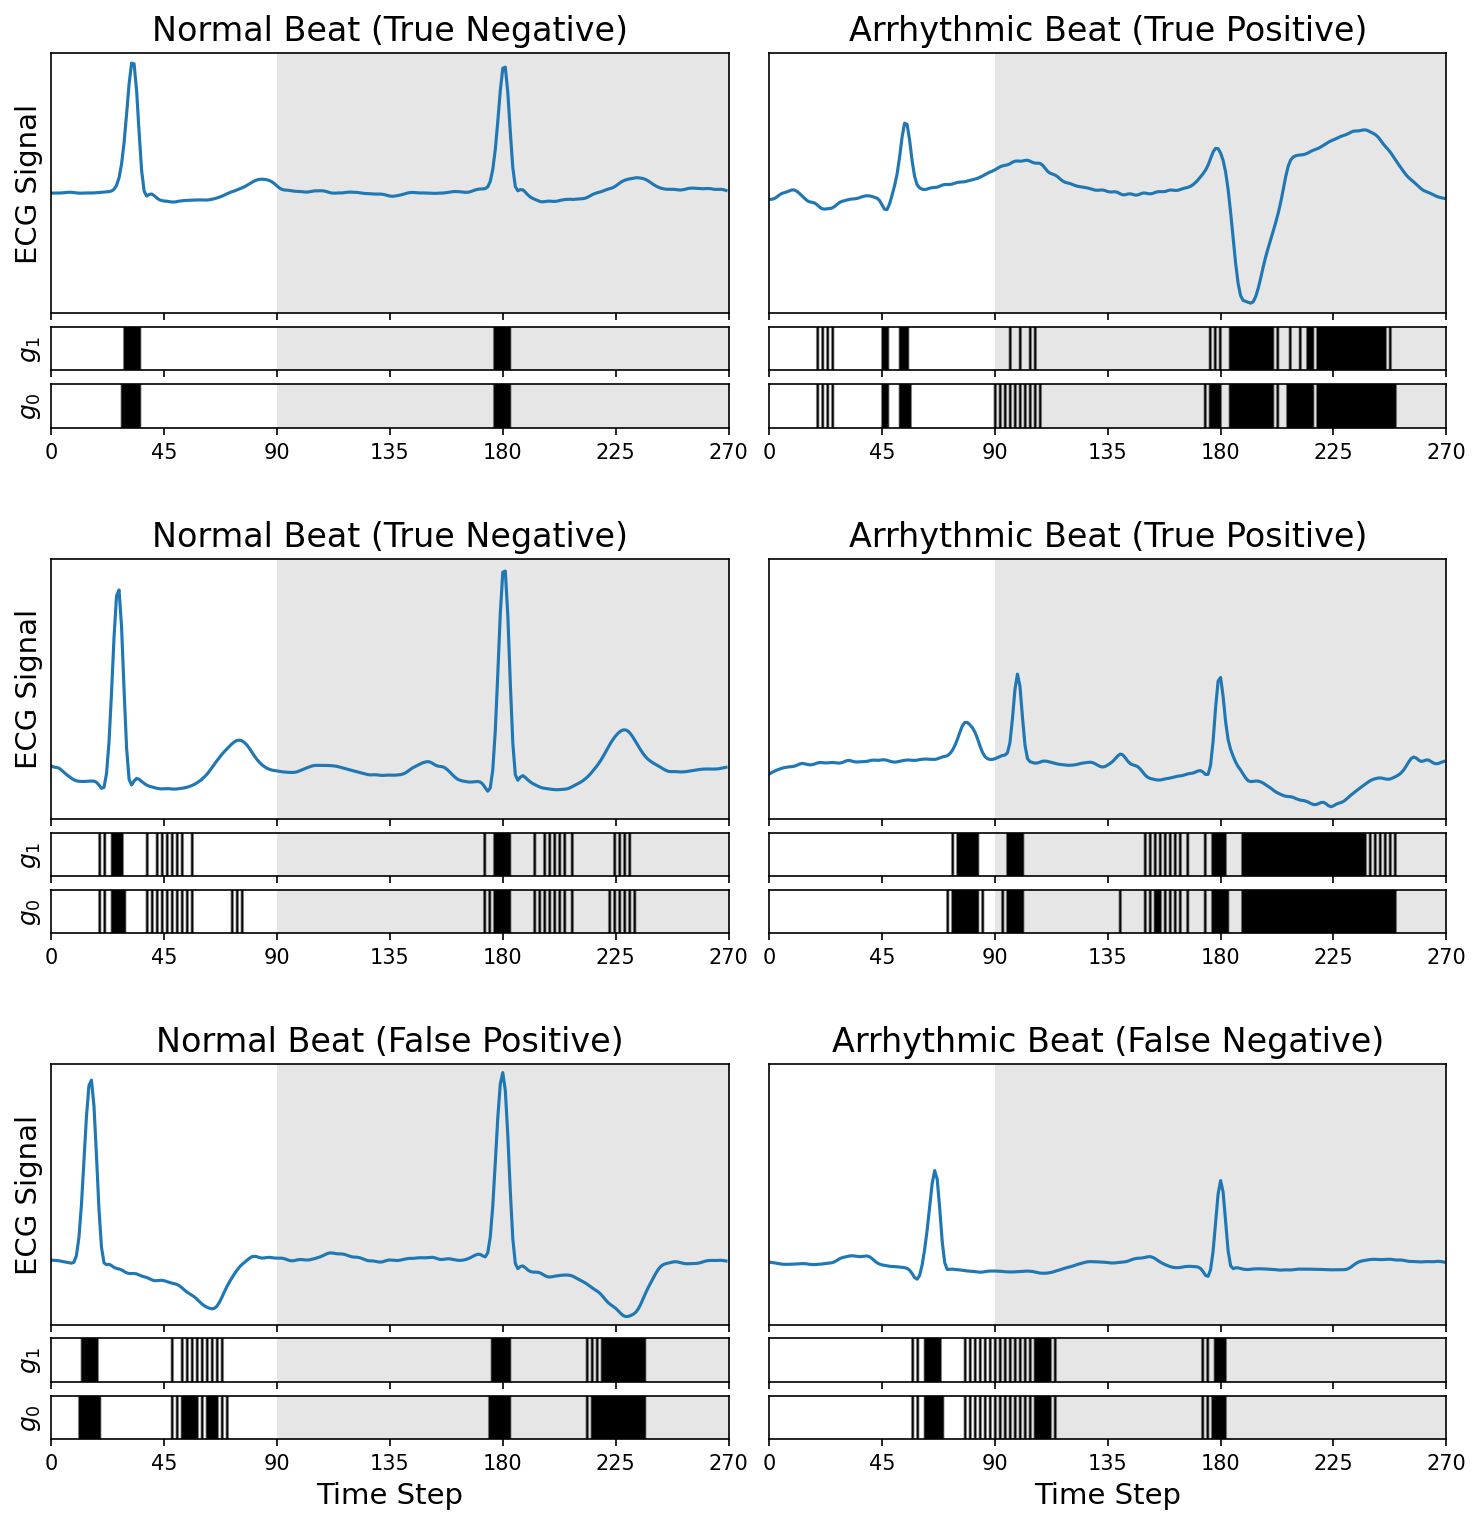

In [65]:
# normal vs arrhythmic beats: rows 1-2 correctly classified, row 3 misclassified.
# uses gates_for from the normal vs arrhythmic cell above.
VARIANT_ROWS = [
    # normal: plain N, record 221 | arrhythmic: ventricular premature beat (V), record 228
    [(1771, 'Normal Beat (True Negative)'), (4243, 'Arrhythmic Beat (True Positive)')],
    # normal: plain N, record 103 | arrhythmic: atrial premature beat (A), record 222
    [(7453, 'Normal Beat (True Negative)'), (6287, 'Arrhythmic Beat (True Positive)')],
    # normal: plain N, record 219 |
    # arrhythmic: atrial premature beat (A) with a normal-looking QRS, record 100
    [(1825, 'Normal Beat (False Positive)'), (4085, 'Arrhythmic Beat (False Negative)')],
]

# fail loudly if a beat's label or prediction doesn't match its title
for pair in VARIANT_ROWS:
    for idx, title in pair:
        is_arrhythmic = title.startswith('Arrhythmic')
        is_correct = '(True' in title
        assert viz_y[idx] == is_arrhythmic, (idx, title)
        assert viz_pred[idx] == (is_arrhythmic == is_correct), (idx, title)

fig = plt.figure(figsize=(12, 12), dpi=150)
outer = fig.add_gridspec(len(VARIANT_ROWS), 2, hspace=0.35, wspace=0.06)

for row, pair in enumerate(VARIANT_ROWS):
    waveforms = [test_dataset[idx][0].numpy() for idx, _ in pair]

    # the two beats in a row share the ECG y-range
    y_min = min(w.min() for w in waveforms) - 0.1
    y_max = max(w.max() for w in waveforms) + 0.1

    for col, ((idx, title), waveform) in enumerate(zip(pair, waveforms)):
        g0, g1 = gates_for(idx)
        x = np.arange(len(g0))

        inner = outer[row, col].subgridspec(3, 1, height_ratios=[3, 0.5, 0.5], hspace=0.12)
        ax_ecg = fig.add_subplot(inner[0])
        ax_g1 = fig.add_subplot(inner[1], sharex=ax_ecg)
        ax_g0 = fig.add_subplot(inner[2], sharex=ax_ecg)

        ax_ecg.plot(x, waveform)
        ax_ecg.set_ylim(y_min, y_max)

        # closed gates are transparent so the beat-span shading shows through them
        for ax, g in ((ax_g1, g1), (ax_g0, g0)):
            ax.imshow(np.ma.masked_equal(g[np.newaxis, :], 0), aspect='auto', cmap='gray_r',
                      extent=[x[0], x[-1], 0, 1], vmin=0, vmax=1, zorder=1)
            ax.axvspan(0, start, color='white', lw=0, zorder=0)

        for ax in (ax_ecg, ax_g1, ax_g0):
            ax.axvspan(start, end, color='0.9', lw=0, zorder=0)
            ax.set_yticks([])
            ax.set_xlim(0, len(x) - 1)
            ax.set_xticks(np.arange(0, len(x) + 1, 45))
            ax.tick_params(axis='x', labelsize=10)
        for ax in (ax_ecg, ax_g1):
            ax.tick_params(axis='x', labelbottom=False)

        ax_ecg.set_title(title, fontsize=16)

        if col == 0:
            ax_ecg.set_ylabel('ECG Signal', fontsize=14)
            ax_g1.set_ylabel('$g_1$', fontsize=12)
            ax_g0.set_ylabel('$g_0$', fontsize=12)
        if row == len(VARIANT_ROWS) - 1:
            ax_g0.set_xlabel('Time Step', fontsize=14)

plt.savefig("../figures/gate_visualization_correct_incorrect.png", dpi=600, bbox_inches="tight", transparent=True)

plt.show()


#### Dark-mode version

The same figure for slides with a black background, laid out 2 × 3: normal beats on the top row, arrhythmic beats on the bottom row, one column per pair. The saved file has a transparent background; the black shown here is only for the notebook preview. It uses the beats in `VARIANT_ROWS` above and saves to `../figures/gate_visualization_correct_incorrect_dark.png`.

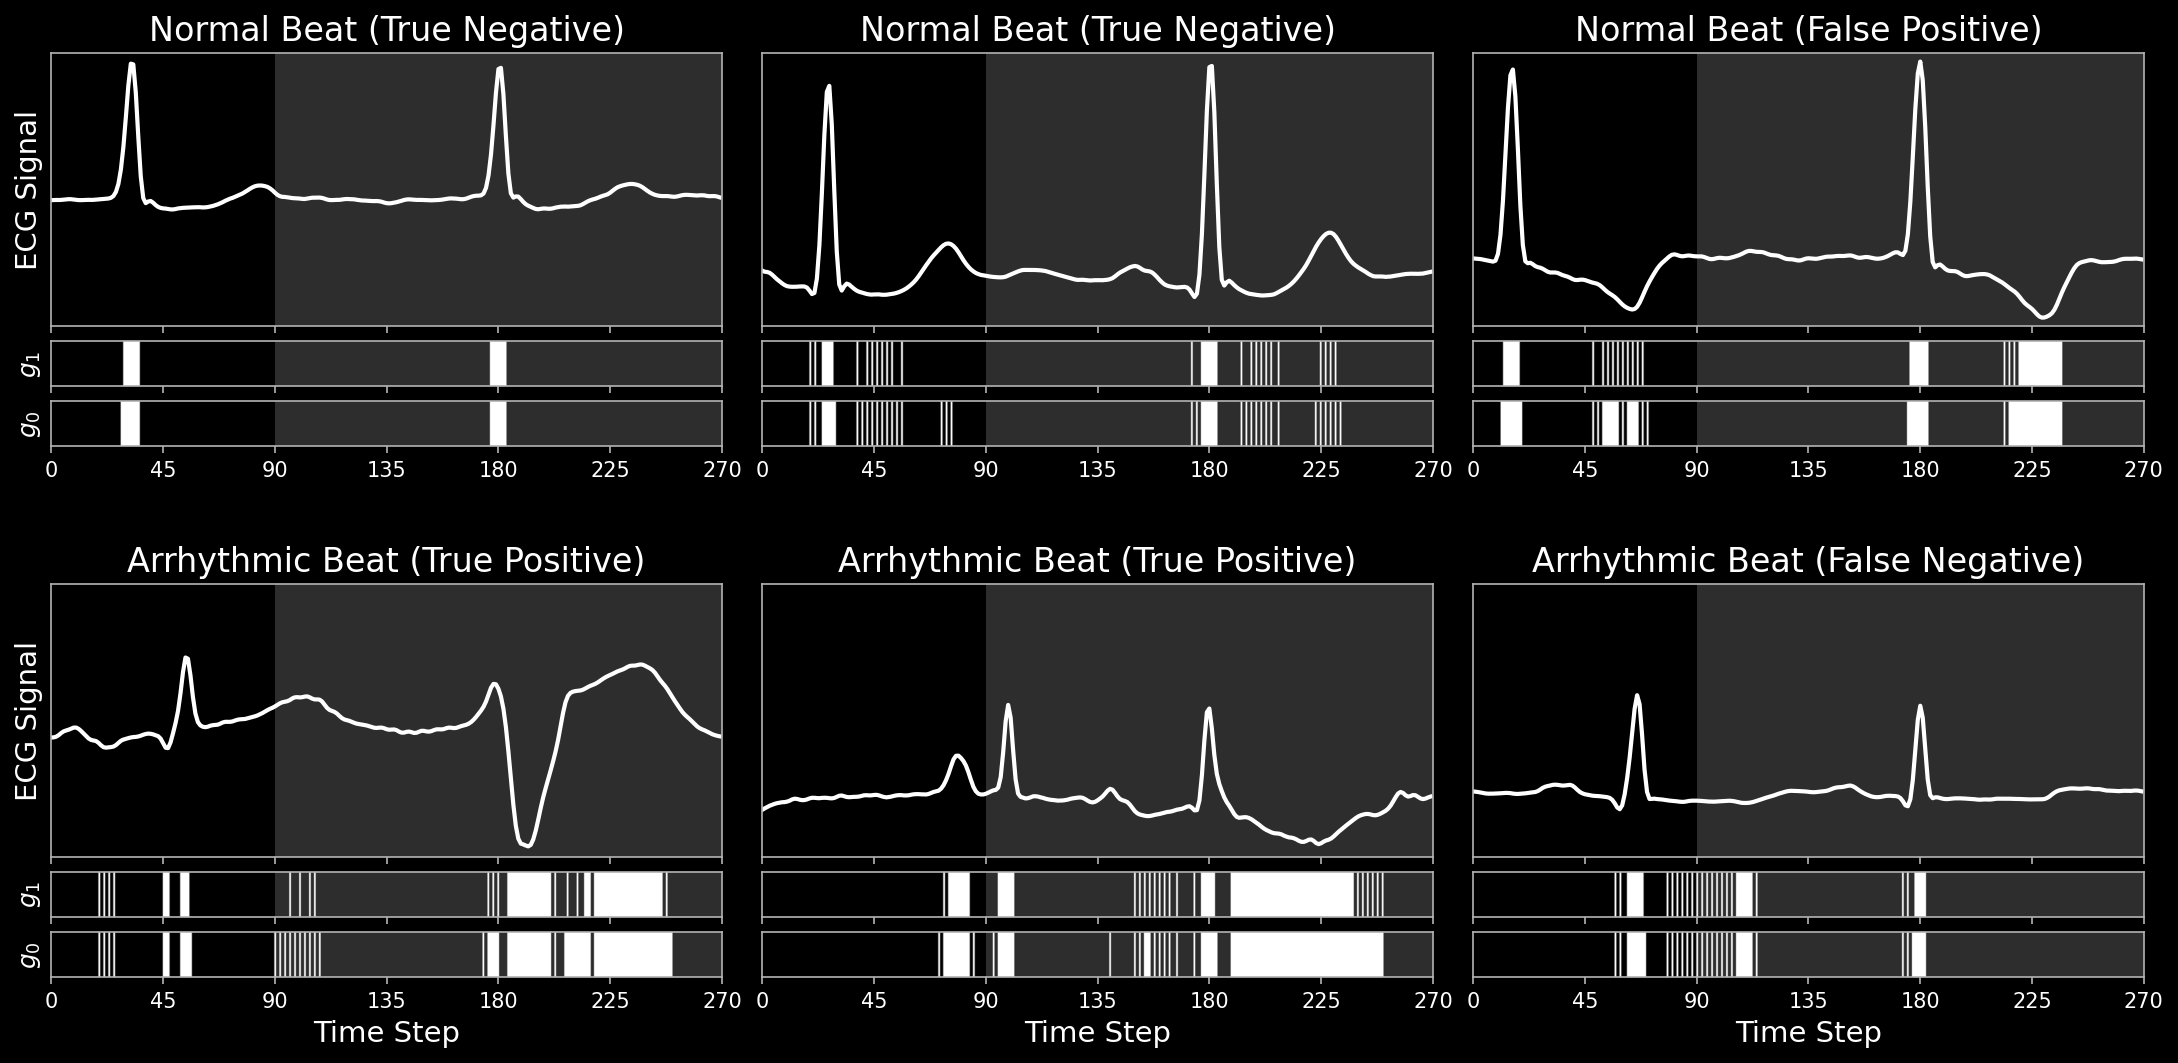

In [73]:
# dark-mode version of the figure above, for slides with a black background: light
# text and axes, white open gates, transparent background in the saved file.
# reuses VARIANT_ROWS (and gates_for), so changing a beat there changes both figures.
# laid out 2 x 3 for slides: normal beats on the top row, arrhythmic beats on the
# bottom row, one column per pair from VARIANT_ROWS.
DARK_TEXT = 'white'
DARK_AXIS = '#b3b3b3'
DARK_ECG = 'white'
DARK_SPAN = (1, 1, 1, 0.18)   # translucent white: reads as dark gray over black

# the black facecolor is only for the notebook preview; savefig(transparent=True) drops it
fig = plt.figure(figsize=(6 * len(VARIANT_ROWS), 8), dpi=150, facecolor='black')
outer = fig.add_gridspec(2, len(VARIANT_ROWS), hspace=0.35, wspace=0.06)

for col, pair in enumerate(VARIANT_ROWS):
    waveforms = [test_dataset[idx][0].numpy() for idx, _ in pair]

    # the two beats of a pair (one column) share the ECG y-range
    y_min = min(w.min() for w in waveforms) - 0.1
    y_max = max(w.max() for w in waveforms) + 0.1

    for row, ((idx, title), waveform) in enumerate(zip(pair, waveforms)):
        g0, g1 = gates_for(idx)
        x = np.arange(len(g0))

        inner = outer[row, col].subgridspec(3, 1, height_ratios=[3, 0.5, 0.5], hspace=0.12)
        ax_ecg = fig.add_subplot(inner[0])
        ax_g1 = fig.add_subplot(inner[1], sharex=ax_ecg)
        ax_g0 = fig.add_subplot(inner[2], sharex=ax_ecg)

        ax_ecg.plot(x, waveform, color=DARK_ECG, linewidth=2)
        ax_ecg.set_ylim(y_min, y_max)

        # open gates in white; closed gates are transparent so the background and
        # the beat-span shading show through
        for ax, g in ((ax_g1, g1), (ax_g0, g0)):
            ax.imshow(np.ma.masked_equal(g[np.newaxis, :], 0), aspect='auto', cmap='gray',
                      extent=[x[0], x[-1], 0, 1], vmin=0, vmax=1, zorder=1)

        for ax in (ax_ecg, ax_g1, ax_g0):
            ax.set_facecolor('black')
            ax.axvspan(start, end, color=DARK_SPAN, lw=0, zorder=0)
            ax.set_yticks([])
            ax.set_xlim(0, len(x) - 1)
            ax.set_xticks(np.arange(0, len(x) + 1, 45))
            ax.tick_params(axis='x', labelsize=10, colors=DARK_AXIS, labelcolor=DARK_TEXT)
            for spine in ax.spines.values():
                spine.set_color(DARK_AXIS)
        for ax in (ax_ecg, ax_g1):
            ax.tick_params(axis='x', labelbottom=False)

        ax_ecg.set_title(title, fontsize=16, color=DARK_TEXT)

        if col == 0:
            ax_ecg.set_ylabel('ECG Signal', fontsize=14, color=DARK_TEXT)
            ax_g1.set_ylabel('$g_1$', fontsize=12, color=DARK_TEXT)
            ax_g0.set_ylabel('$g_0$', fontsize=12, color=DARK_TEXT)
        if row == 1:
            ax_g0.set_xlabel('Time Step', fontsize=14, color=DARK_TEXT)

plt.savefig("../figures/gate_visualization_correct_incorrect_dark.png", dpi=600, bbox_inches="tight", transparent=True)

plt.show()


#### Normal beats

**Correct: plain N, record 221.** The gates open for the QRS and close again. All three layers fire one short burst at the R peak and are silent elsewhere, so the score stops at 0.025.

**Incorrect: right bundle branch block beat (R), record 212.** The rhythm is normal (RR 0.98× local), but the wide, notched QRS holds the gates open. Layer 2 keeps firing to about step 200, and the T wave adds a smaller burst near step 225. The score crosses the threshold just after the R peak, the same response a ventricular beat gets.

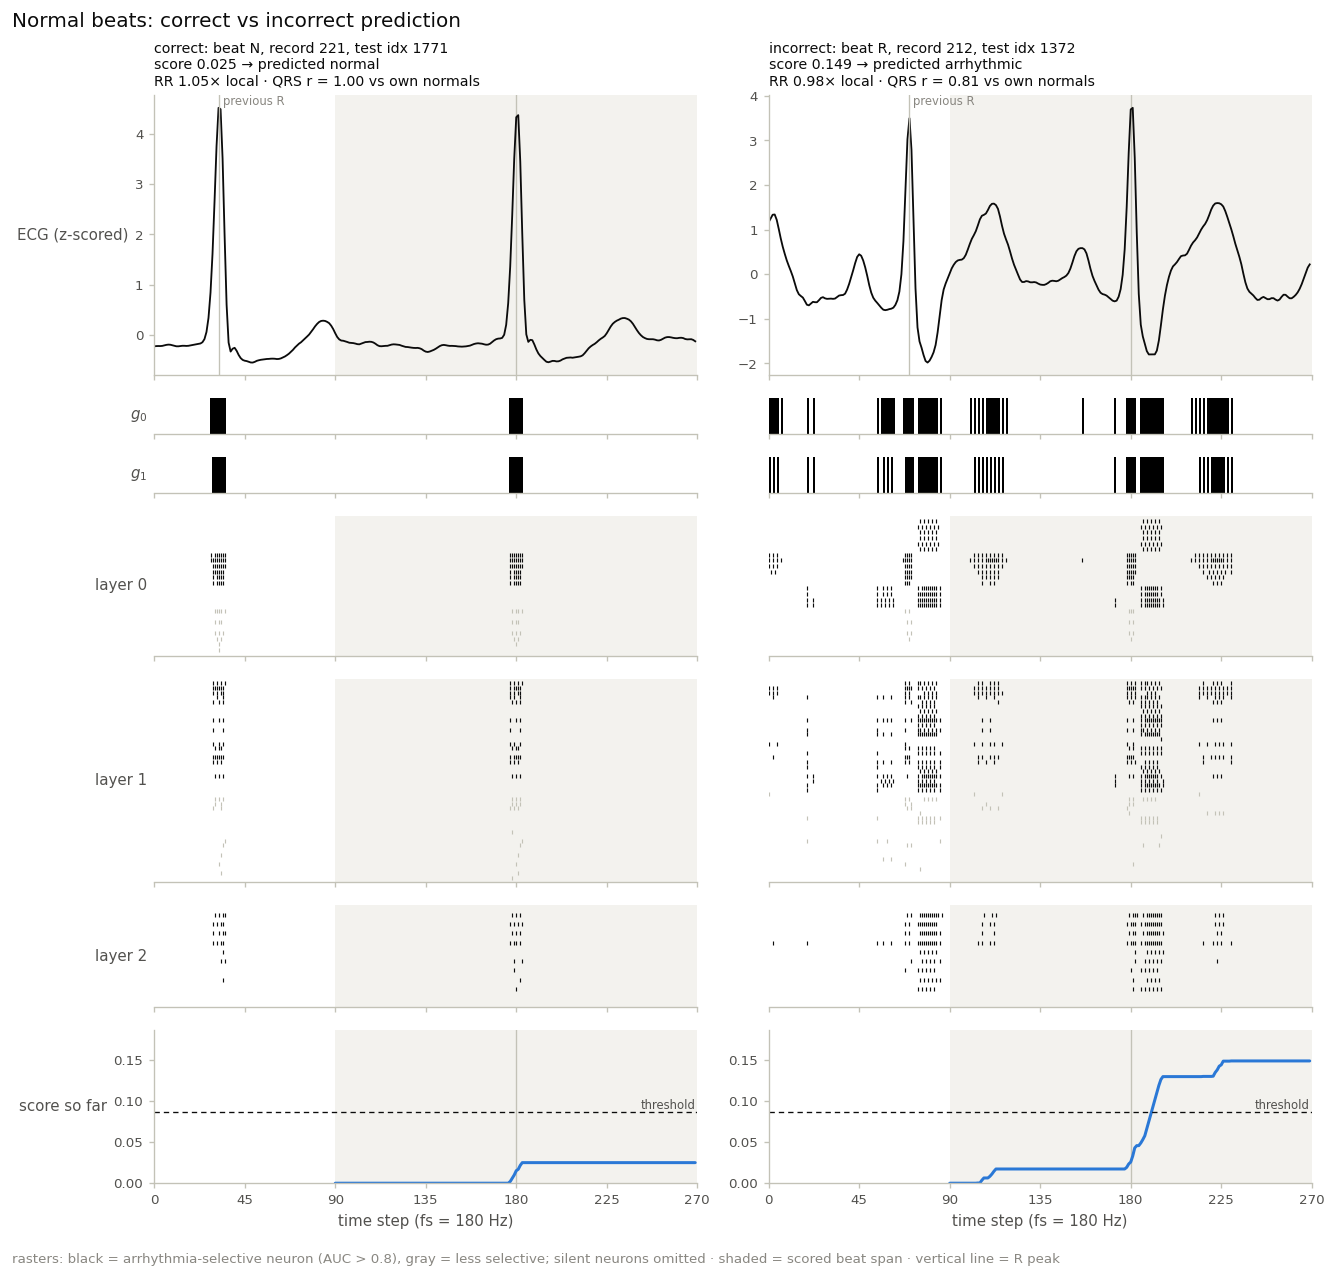

In [67]:
plot_pair('normal')


#### Supraventricular beats

**Correct: atrial premature beat (A), record 222.** Premature (RR 0.73× local). Its QRS gives only a brief burst. The score crosses the threshold on the long ST depression that follows (steps ~195–245), where the gates stay open and all three layers fire continuously; 89% of its score comes from the QRS onward.

**Incorrect: atrial premature beat (A), record 100.** Just as premature (RR 0.78× local), but its QRS is indistinguishable from this patient's normal beats (r = 1.00). The network responds exactly as it does to the correct normal beat above: one burst at the R peak, score 0.025. Nothing in the rasters reflects that the beat came early.

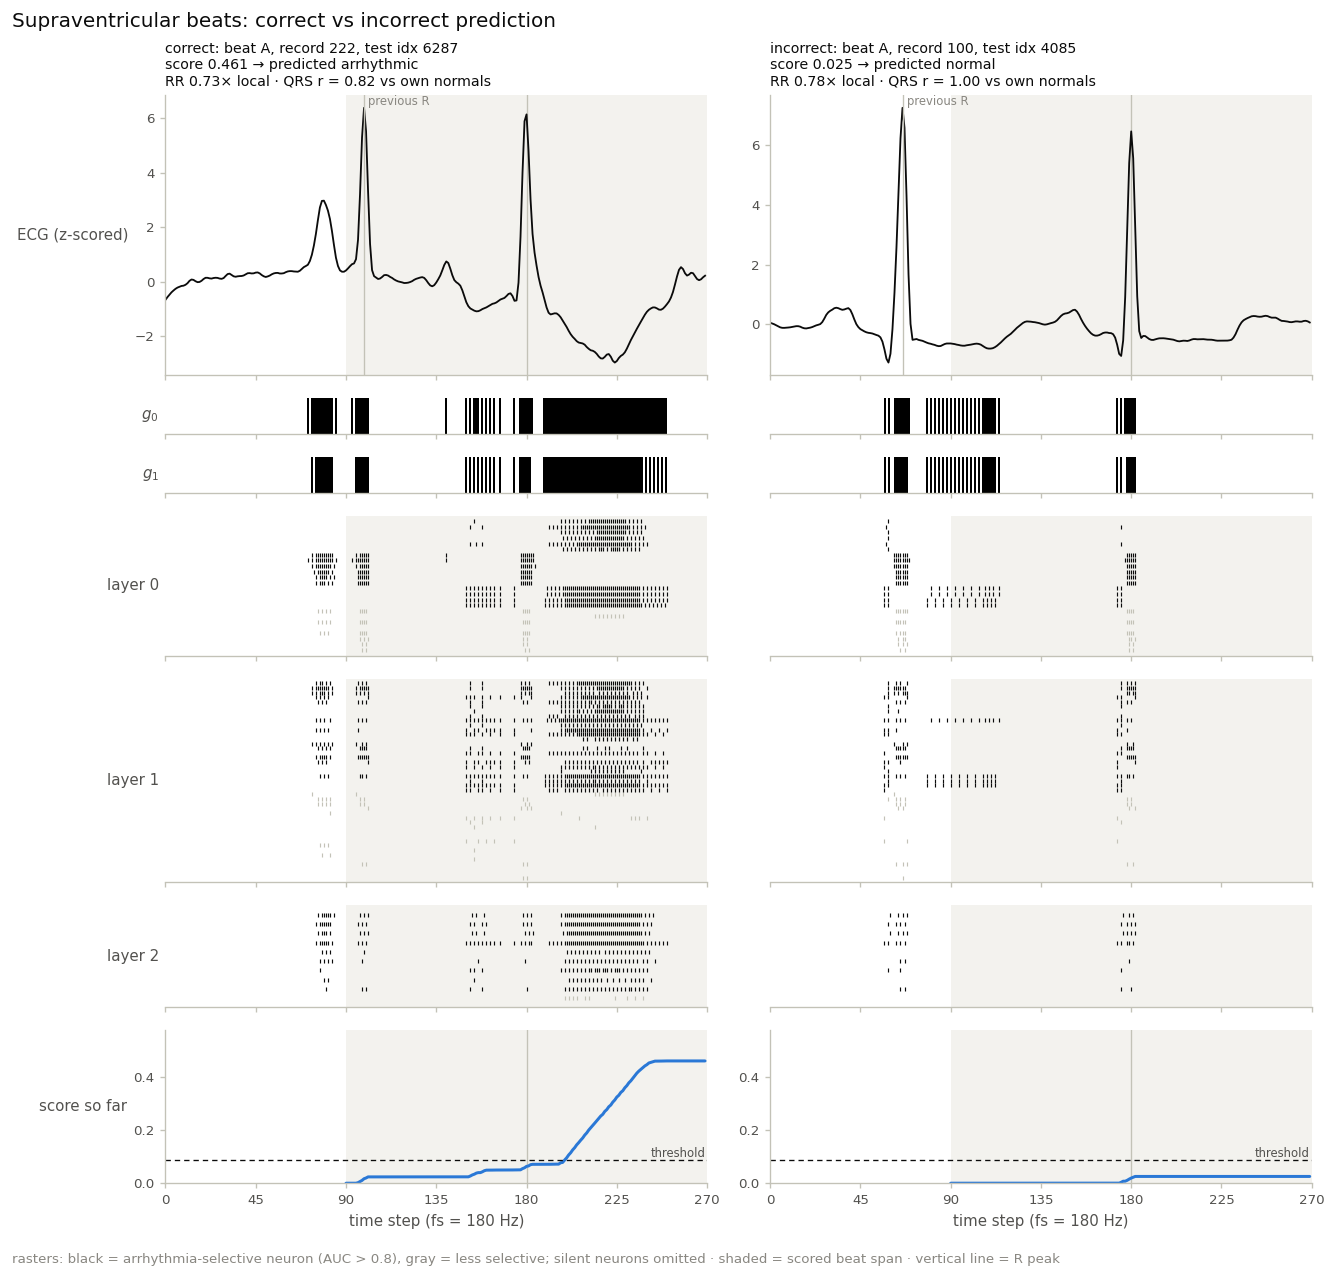

In [68]:
plot_pair('supraventricular')


#### Ventricular beats

**Correct: ventricular premature beat (V), record 228.** A wide QRS with a deep negative deflection, followed by a large T wave. The gates open at the R peak and stay open through both. Layer 2 fires in two long runs (about steps 185–205 and 220–250), and the score passes the threshold shortly after the R peak.

**Incorrect: ventricular premature beat (V), record 210.** Annotated V, but its QRS correlates 0.99 with this patient's normal beats. The network gives it the normal-beat response. There are short bursts at the previous beat, which falls inside the span because this beat is early (RR 0.66× local), and at its own R peak, for a score of 0.057.

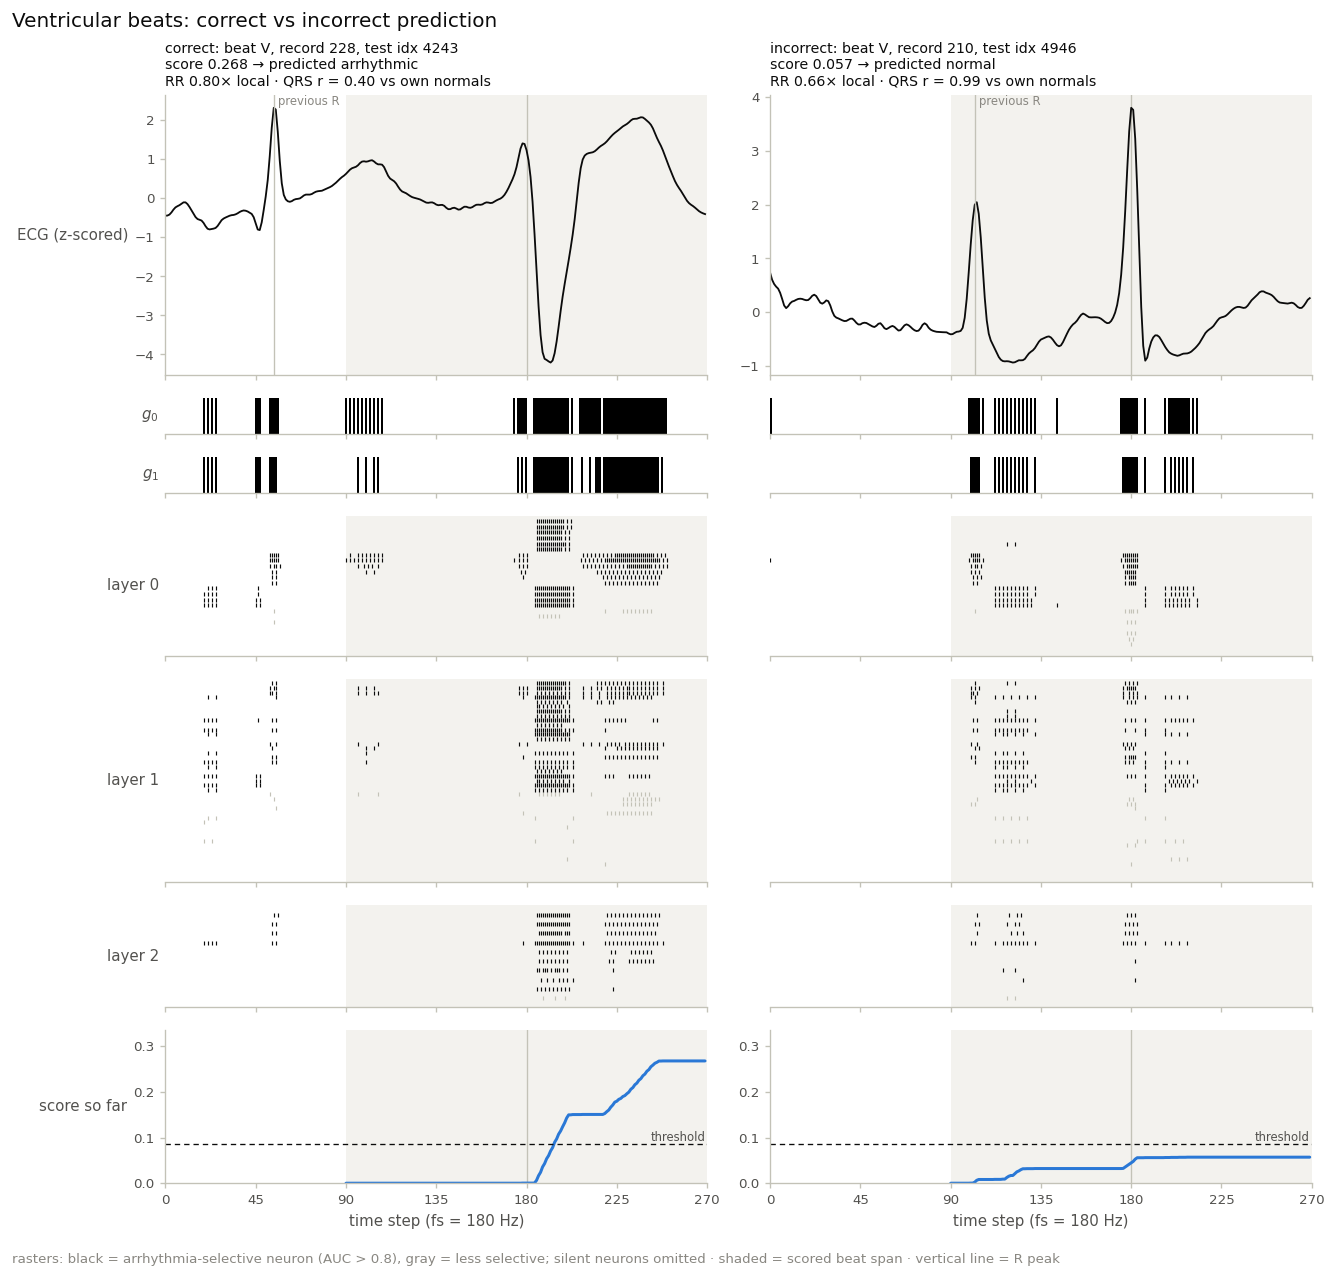

In [69]:
plot_pair('ventricular')


### Other candidates

Each list is ranked by its category's rule; `*` marks the beat used above. To redraw with a different beat, change its index in `EXAMPLES`, rerun that cell (which runs `check_examples`), then rerun `plot_pair`.

In [70]:
# candidate examples, ranked by the rule each category's example is picked with.
# EXAMPLES above was chosen from these lists after looking at the top few; * marks those beats.

# noise = second-difference energy relative to the signal; < 0.08 keeps ~85% of beats
noise = np.abs(np.diff(acts['waveform'], 2, axis=1)).mean(1) / (acts['waveform'].std(1) + 1e-6)


def row_corr(rows, template):
    # correlation of every row with one template
    a = rows - rows.mean(1, keepdims=True)
    b = template - template.mean()
    return (a @ b) / (np.linalg.norm(a, axis=1) * np.linalg.norm(b) + 1e-12)


def candidates(symbols, flagged, rank_by, where=True, k=5):
    '''top-k clean beats of these symbols with this prediction, one per record, by ascending rank_by'''
    m = np.isin(beat_symbol, symbols) & (viz_pred == flagged) & (noise < 0.08) & ~np.isnan(rank_by) & where
    ranked = np.where(m)[0][np.argsort(rank_by[m], kind='stable')]
    picked, seen = [], set()
    for i in ranked:
        if record[i] not in seen:
            picked.append(int(i))
            seen.add(record[i])
        if len(picked) == k:
            break
    return picked


span = slice(start, end)
on_time = np.abs(prematurity - 1) < 0.1

normal_like = row_corr(acts['waveform'][:, span], acts['waveform'][aami == 0, span].mean(0))
v_like = row_corr(acts['waveform'][:, span], acts['waveform'][(beat_symbol == 'V') & viz_pred, span].mean(0))
low_normal_score = acts['score'] <= np.percentile(acts['score'][(aami == 0) & ~viz_pred], 30)
v_scores = acts['score'][(beat_symbol == 'V') & viz_pred]
mid_v_score = (acts['score'] > np.percentile(v_scores, 50)) & (acts['score'] < np.percentile(v_scores, 90))
r_error_median = np.median(acts['score'][(beat_symbol == 'R') & viz_pred])

CANDIDATES = {
    ('normal', 'correct'): (
        'on time, low score, closest to the mean normal waveform',
        candidates(['N'], False, -normal_like, where=on_time & low_normal_score & (normal_like > 0.9))),
    ('normal', 'incorrect'): (
        'right bundle branch block beat with a typical score for that error',
        candidates(['R'], True, np.abs(acts['score'] - r_error_median))),
    ('supraventricular', 'correct'): (
        'premature (RR < 0.85x local), >= 70% of the score from its own QRS onward, QRS least like own normals, not record 232',
        candidates(['A'], True, shape_similarity, where=premature & (record != 232) & (own_beat_share >= 0.7))),
    ('supraventricular', 'incorrect'): (
        'premature (RR < 0.85x local), QRS most like own normals',
        candidates(['A'], False, -shape_similarity, where=premature)),
    ('ventricular', 'correct'): (
        'previous beat outside the span, mid-range score, closest to the mean detected V waveform',
        candidates(['V'], True, -v_like, where=(rr_prev > 100) & mid_v_score)),
    ('ventricular', 'incorrect'): (
        'QRS most like own normals',
        candidates(['V'], False, -shape_similarity)),
}


def show_candidates(examples=None):
    chosen = {i for pair in (examples or {}).values() for _, i in pair}
    for (group, outcome), (rule, idxs) in CANDIDATES.items():
        print(f'{group}, {outcome} -- {rule}')
        print('    ' + ', '.join(f'{i}{"*" if i in chosen else ""} (rec {record[i]}, score {acts["score"][i]:.3f}, '
                                 f'RR {prematurity[i]:.2f}x, r {shape_similarity[i]:.2f})' for i in idxs))


show_candidates(EXAMPLES)


normal, correct -- on time, low score, closest to the mean normal waveform
    1771* (rec 221, score 0.025, RR 1.05x, r 1.00), 6053 (rec 234, score 0.025, RR 1.03x, r 0.99), 3415 (rec 200, score 0.019, RR 1.00x, r 1.00), 7453 (rec 103, score 0.025, RR 1.02x, r 0.99), 4176 (rec 202, score 0.021, RR 1.03x, r 0.99)
normal, incorrect -- right bundle branch block beat with a typical score for that error
    1381 (rec 231, score 0.149, RR 0.92x, r 0.71), 1372* (rec 212, score 0.149, RR 0.98x, r 0.81), 5336 (rec 232, score 0.144, RR 2.32x, r nan)
supraventricular, correct -- premature (RR < 0.85x local), >= 70% of the score from its own QRS onward, QRS least like own normals, not record 232
    2795 (rec 213, score 0.200, RR 0.71x, r 0.50), 7634 (rec 202, score 0.740, RR 0.38x, r 0.76), 6287* (rec 222, score 0.461, RR 0.73x, r 0.82)
supraventricular, incorrect -- premature (RR < 0.85x local), QRS most like own normals
    4085* (rec 100, score 0.025, RR 0.78x, r 1.00), 7670 (rec 202, score 0.